In [5]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"

# ── Chargement ────────────────────────────────────────────────────────────
ds_alti = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)
ds_mdt = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_eur_phy-mdt_my_l4-0.0625deg_P20Y"
               r"_mdt-v-u_4.97W-9.97E_35.03N-40.97N_2003-01-01.nc"
)

# ── TEST FINAL NaN ────────────────────────────────────────────────────────
nan_ts = ds_alti['sla'].isnull().mean(dim=['latitude','longitude'])
print("TEST NaN — variation temporelle :")
print(f"  Min = {float(nan_ts.min())*100:.2f}%")
print(f"  Max = {float(nan_ts.max())*100:.2f}%")
print(f"  Écart-type = {float(nan_ts.std())*100:.4f}%")
print("  → Si écart-type < 0.1% : masque terre fixe ✅")

# Vérification point pleine mer (centre bassin algérien)
pt = ds_alti['sla'].sel(longitude=3.0, latitude=37.5, method='nearest')
print(f"\nPoint pleine mer (3°E, 37.5°N) : {float(pt.isnull().mean())*100:.1f}% NaN")
print("  → Doit être 0% ✅\n")

# ── CALCUL EKE ────────────────────────────────────────────────────────────
print("Calcul EKE...")
eke = 0.5 * (ds_alti['ugosa']**2 + ds_alti['vgosa']**2) * 1e4  # cm²/s²
eke.attrs = {'long_name': 'Eddy Kinetic Energy', 'units': 'cm²/s²'}

# ── MOYENNES TEMPORELLES ──────────────────────────────────────────────────
print("Calcul des moyennes temporelles 1993–2023...")
adt_mean  = ds_alti['adt'].mean('time')
sla_mean  = ds_alti['sla'].mean('time')
eke_mean  = eke.mean('time')
ugos_mean = ds_alti['ugos'].mean('time')
vgos_mean = ds_alti['vgos'].mean('time')

# MDT interpolé sur la grille allsat pour vérification
mdt_interp = ds_mdt['mdt'].interp(
    latitude=ds_alti.latitude,
    longitude=ds_alti.longitude
)

# ── FIGURE 1 — PUBLICATION QUALITY ───────────────────────────────────────
proj = ccrs.PlateCarree()
fig = plt.figure(figsize=(18, 12))
fig.patch.set_facecolor('white')

lon_min, lon_max = -5, 10
lat_min, lat_max = 35, 41

# ── Sous-figure A : ADT moyenne (circulation générale) ────────────────────
ax1 = fig.add_subplot(2, 2, 1, projection=proj)
ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf1 = ax1.contourf(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=30, cmap=cmocean.cm.deep, transform=proj
)
# Contours SSH (lignes de courant)
cs1 = ax1.contour(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=15, colors='white', linewidths=0.4, alpha=0.6, transform=proj
)

# Vecteurs de courant (sous-échantillonnage pour lisibilité)
step = 4
q1 = ax1.quiver(
    ugos_mean.longitude.values[::step],
    ugos_mean.latitude.values[::step],
    ugos_mean.values[::step, ::step],
    vgos_mean.values[::step, ::step],
    transform=proj, scale=3, width=0.002,
    color='white', alpha=0.7
)
ax1.quiverkey(q1, 0.88, 0.05, 0.3, '0.3 m/s', labelpos='E',
              color='white', labelcolor='white', fontproperties={'size': 8})

ax1.add_feature(cfeature.LAND, facecolor='#d4c9a8', zorder=5)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=6)
ax1.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=':', zorder=6)

gl1 = ax1.gridlines(draw_labels=True, linewidth=0.3, color='gray',
                     alpha=0.5, linestyle='--')
gl1.top_labels = False
gl1.right_labels = False
gl1.xformatter = mticker.FuncFormatter(
    lambda x, _: f"{abs(x):.0f}°{'W' if x < 0 else 'E'}"
)
gl1.yformatter = mticker.FuncFormatter(
    lambda y, _: f"{abs(y):.0f}°{'S' if y < 0 else 'N'}"
)
gl1.xlabel_style = {'size': 8}
gl1.ylabel_style = {'size': 8}

plt.colorbar(cf1, ax=ax1, orientation='horizontal', pad=0.04,
             shrink=0.85, label='ADT (m)', aspect=30)
ax1.set_title('(a) ADT moyenne 1993–2023\nCirculation générale surface', fontsize=10)

# ── Sous-figure B : EKE moyenne ───────────────────────────────────────────
ax2 = fig.add_subplot(2, 2, 2, projection=proj)
ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf2 = ax2.contourf(
    eke_mean.longitude, eke_mean.latitude, eke_mean.values,
    levels=np.linspace(0, eke_mean.quantile(0.98).values, 25),
    cmap=cmocean.cm.matter, transform=proj, extend='max'
)
# Contours ADT superposés pour référence
cs2 = ax2.contour(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=10, colors='black', linewidths=0.35, alpha=0.5, transform=proj
)

ax2.add_feature(cfeature.LAND, facecolor='#d4c9a8', zorder=5)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=6)
ax2.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=':', zorder=6)
gl2 = ax2.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
gl2.top_labels = False; gl2.right_labels = False
gl2.xlabel_style = {'size': 8}; gl2.ylabel_style = {'size': 8}
plt.colorbar(cf2, ax=ax2, orientation='horizontal', pad=0.04,
             shrink=0.85, label='EKE (cm²/s²)', aspect=30)
ax2.set_title('(b) EKE moyenne 1993–2023\nZones d\'activité méso-échelle', fontsize=10)

# ── Sous-figure C : SLA std (variabilité) ────────────────────────────────
ax3 = fig.add_subplot(2, 2, 3, projection=proj)
ax3.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

sla_std = ds_alti['sla'].std('time')
cf3 = ax3.contourf(
    sla_std.longitude, sla_std.latitude, sla_std.values * 100,  # en cm
    levels=25, cmap=cmocean.cm.amp, transform=proj
)

ax3.add_feature(cfeature.LAND, facecolor='#d4c9a8', zorder=5)
ax3.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=6)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=':', zorder=6)
gl3 = ax3.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
gl3.top_labels = False; gl3.right_labels = False
gl3.xlabel_style = {'size': 8}; gl3.ylabel_style = {'size': 8}
plt.colorbar(cf3, ax=ax3, orientation='horizontal', pad=0.04,
             shrink=0.85, label='SLA std (cm)', aspect=30)
ax3.set_title('(c) Variabilité SLA 1993–2023\nÉcart-type temporel', fontsize=10)

# ── Sous-figure D : MDT (topographie dynamique moyenne) ──────────────────
ax4 = fig.add_subplot(2, 2, 4, projection=proj)
ax4.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf4 = ax4.contourf(
    ds_mdt['mdt'].longitude, ds_mdt['mdt'].latitude, ds_mdt['mdt'].values,
    levels=30, cmap=cmocean.cm.curl, transform=proj
)
# Vecteurs MDT
step_mdt = 3
ax4.quiver(
    ds_mdt['mdt'].longitude.values[::step_mdt],
    ds_mdt['mdt'].latitude.values[::step_mdt],
    ds_mdt['u'].values[::step_mdt, ::step_mdt],
    ds_mdt['v'].values[::step_mdt, ::step_mdt],
    transform=proj, scale=5, width=0.002, color='black', alpha=0.5
)

ax4.add_feature(cfeature.LAND, facecolor='#d4c9a8', zorder=5)
ax4.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=6)
ax4.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=':', zorder=6)
gl4 = ax4.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
gl4.top_labels = False; gl4.right_labels = False
gl4.xlabel_style = {'size': 8}; gl4.ylabel_style = {'size': 8}
plt.colorbar(cf4, ax=ax4, orientation='horizontal', pad=0.04,
             shrink=0.85, label='MDT (m)', aspect=30)
ax4.set_title('(d) MDT EUR 2024\nTopographie dynamique moyenne', fontsize=10)

# ── Titre général ─────────────────────────────────────────────────────────
fig.suptitle(
    'Bassin algérien — Caractérisation de la circulation de surface\n'
    'CMEMS DUACS DT-2024 · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)

plt.tight_layout(h_pad=3, w_pad=2)

# ── Sauvegarde ────────────────────────────────────────────────────────────
OUTPUT = DATA_DIR + r"\FIGURES\Fig01_circulation_surface_1993_2023.png"
os.makedirs(DATA_DIR + r"\FIGURES", exist_ok=True)
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"\nFigure sauvegardée → {OUTPUT}")
plt.show()

ds_alti.close()
ds_mdt.close()

SyntaxError: invalid character '→' (U+2192) (3477560989.py, line 201)

TEST NaN — variation temporelle :
  Min          = 44.08%
  Max          = 44.08%
  Écart-type   = 0.0000%
  → Si écart-type < 0.1% : masque terre fixe ✅

Point pleine mer (3°E, 37.5°N) : 0.0% NaN
  → Doit être 0% ✅

Calcul EKE...
Calcul des moyennes temporelles 1993–2023...
Calculs terminés. Génération de la figure...

Figure sauvegardée → C:\Users\kikk\CLAUDE ARTICLE DATA\FIGURES\Fig01_circulation_surface_1993_2023.png


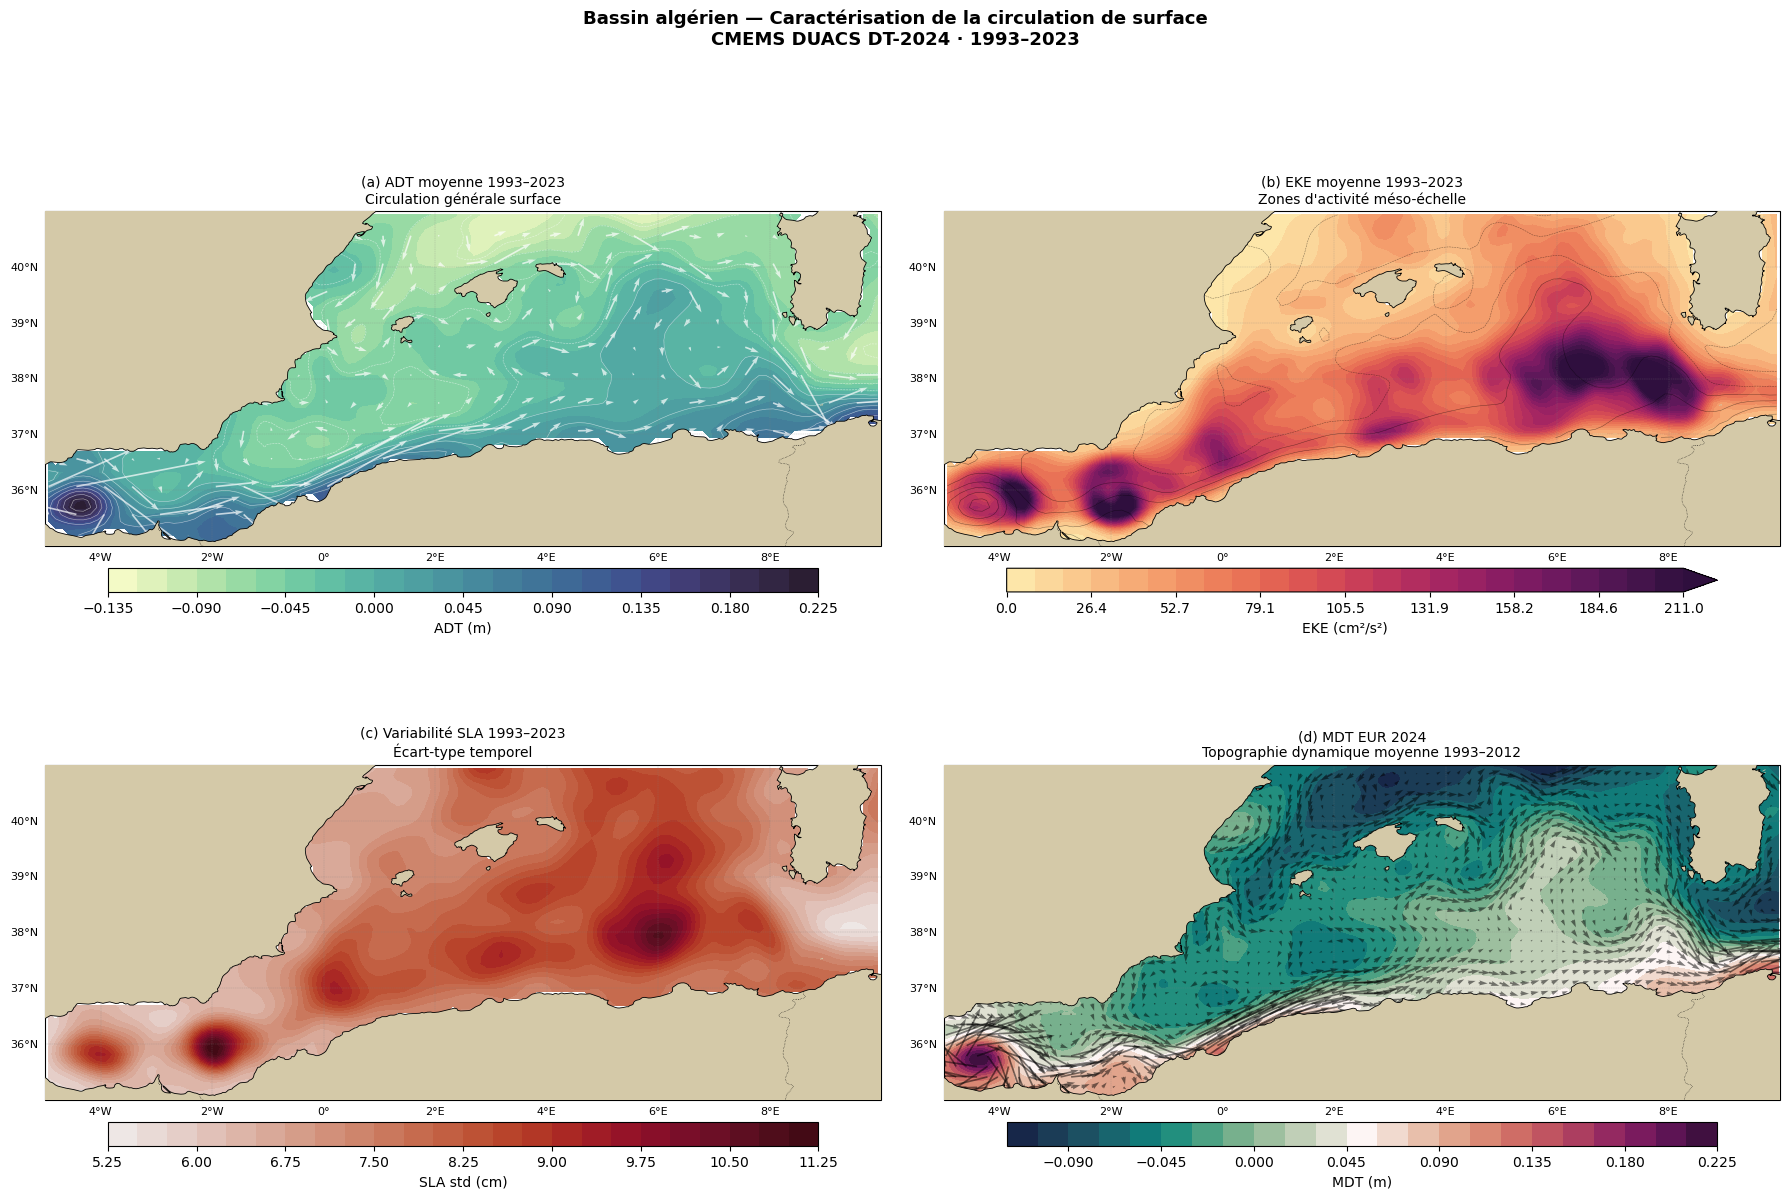

In [7]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import os
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"

# ═══════════════════════════════════════════════════════════════════════════
# CHARGEMENT
# ═══════════════════════════════════════════════════════════════════════════
ds_alti = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)
ds_mdt = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_eur_phy-mdt_my_l4-0.0625deg_P20Y"
               r"_mdt-v-u_4.97W-9.97E_35.03N-40.97N_2003-01-01.nc"
)

# ═══════════════════════════════════════════════════════════════════════════
# TEST NaN (validation)
# ═══════════════════════════════════════════════════════════════════════════
nan_ts = ds_alti['sla'].isnull().mean(dim=['latitude', 'longitude'])
print("TEST NaN — variation temporelle :")
print(f"  Min          = {float(nan_ts.min()) * 100:.2f}%")
print(f"  Max          = {float(nan_ts.max()) * 100:.2f}%")
print(f"  Écart-type   = {float(nan_ts.std()) * 100:.4f}%")
print("  → Si écart-type < 0.1% : masque terre fixe ✅\n")

pt = ds_alti['sla'].sel(longitude=3.0, latitude=37.5, method='nearest')
print(f"Point pleine mer (3°E, 37.5°N) : {float(pt.isnull().mean()) * 100:.1f}% NaN")
print("  → Doit être 0% ✅\n")

# ═══════════════════════════════════════════════════════════════════════════
# CALCULS
# ═══════════════════════════════════════════════════════════════════════════
print("Calcul EKE...")
eke = 0.5 * (ds_alti['ugosa']**2 + ds_alti['vgosa']**2) * 1e4   # cm²/s²

print("Calcul des moyennes temporelles 1993–2023...")
adt_mean  = ds_alti['adt'].mean('time')
sla_std   = ds_alti['sla'].std('time')
eke_mean  = eke.mean('time')
ugos_mean = ds_alti['ugos'].mean('time')
vgos_mean = ds_alti['vgos'].mean('time')

# MDT — squeeze() supprime la dimension temporelle parasite (time=1)
mdt_2d = ds_mdt['mdt'].squeeze()
mdt_u  = ds_mdt['u'].squeeze()
mdt_v  = ds_mdt['v'].squeeze()

print("Calculs terminés. Génération de la figure...\n")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE
# ═══════════════════════════════════════════════════════════════════════════
proj = ccrs.PlateCarree()
lon_min, lon_max = -5, 10
lat_min, lat_max = 35, 41

fig = plt.figure(figsize=(18, 12))
fig.patch.set_facecolor('white')

LAND_COLOR  = '#d4c9a8'
GRID_KW     = dict(linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
LABEL_KW    = {'size': 8}

def add_geo(ax):
    """Ajoute terre, côtes, frontières et grille à un GeoAxes."""
    ax.add_feature(cfeature.LAND,      facecolor=LAND_COLOR, zorder=5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6,         zorder=6)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', zorder=6)
    gl = ax.gridlines(draw_labels=True, **GRID_KW)
    gl.top_labels   = False
    gl.right_labels = False
    gl.xlabel_style = LABEL_KW
    gl.ylabel_style = LABEL_KW
    return gl

# ───────────────────────────────────────────────────────────────────────────
# Panneau (a) — ADT moyenne + vecteurs courant
# ───────────────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(2, 2, 1, projection=proj)
ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf1 = ax1.contourf(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=30, cmap=cmocean.cm.deep, transform=proj
)
ax1.contour(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=15, colors='white', linewidths=0.4, alpha=0.6, transform=proj
)

step = 4
q1 = ax1.quiver(
    ugos_mean.longitude.values[::step],
    ugos_mean.latitude.values[::step],
    ugos_mean.values[::step, ::step],
    vgos_mean.values[::step, ::step],
    transform=proj, scale=3, width=0.002,
    color='white', alpha=0.7
)
ax1.quiverkey(q1, 0.88, 0.05, 0.3, '0.3 m/s',
              labelpos='E', color='white', labelcolor='white',
              fontproperties={'size': 8})

add_geo(ax1)
plt.colorbar(cf1, ax=ax1, orientation='horizontal',
             pad=0.04, shrink=0.85, label='ADT (m)', aspect=30)
ax1.set_title('(a) ADT moyenne 1993–2023\nCirculation générale surface', fontsize=10)

# ───────────────────────────────────────────────────────────────────────────
# Panneau (b) — EKE moyenne
# ───────────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(2, 2, 2, projection=proj)
ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

eke_max = float(eke_mean.quantile(0.98).values)
cf2 = ax2.contourf(
    eke_mean.longitude, eke_mean.latitude, eke_mean.values,
    levels=np.linspace(0, eke_max, 25),
    cmap=cmocean.cm.matter, transform=proj, extend='max'
)
ax2.contour(
    adt_mean.longitude, adt_mean.latitude, adt_mean.values,
    levels=10, colors='black', linewidths=0.35, alpha=0.5, transform=proj
)

add_geo(ax2)
plt.colorbar(cf2, ax=ax2, orientation='horizontal',
             pad=0.04, shrink=0.85, label='EKE (cm²/s²)', aspect=30)
ax2.set_title("(b) EKE moyenne 1993–2023\nZones d'activité méso-échelle", fontsize=10)

# ───────────────────────────────────────────────────────────────────────────
# Panneau (c) — SLA std (variabilité temporelle)
# ───────────────────────────────────────────────────────────────────────────
ax3 = fig.add_subplot(2, 2, 3, projection=proj)
ax3.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf3 = ax3.contourf(
    sla_std.longitude, sla_std.latitude, sla_std.values * 100,   # → cm
    levels=25, cmap=cmocean.cm.amp, transform=proj
)

add_geo(ax3)
plt.colorbar(cf3, ax=ax3, orientation='horizontal',
             pad=0.04, shrink=0.85, label='SLA std (cm)', aspect=30)
ax3.set_title('(c) Variabilité SLA 1993–2023\nÉcart-type temporel', fontsize=10)

# ───────────────────────────────────────────────────────────────────────────
# Panneau (d) — MDT + vecteurs
# ───────────────────────────────────────────────────────────────────────────
ax4 = fig.add_subplot(2, 2, 4, projection=proj)
ax4.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

cf4 = ax4.contourf(
    mdt_2d.longitude, mdt_2d.latitude, mdt_2d.values,
    levels=30, cmap=cmocean.cm.curl, transform=proj
)

step_mdt = 3
ax4.quiver(
    mdt_2d.longitude.values[::step_mdt],
    mdt_2d.latitude.values[::step_mdt],
    mdt_u.values[::step_mdt, ::step_mdt],
    mdt_v.values[::step_mdt, ::step_mdt],
    transform=proj, scale=5, width=0.002,
    color='black', alpha=0.5
)

add_geo(ax4)
plt.colorbar(cf4, ax=ax4, orientation='horizontal',
             pad=0.04, shrink=0.85, label='MDT (m)', aspect=30)
ax4.set_title('(d) MDT EUR 2024\nTopographie dynamique moyenne 1993–2012', fontsize=10)

# ═══════════════════════════════════════════════════════════════════════════
# TITRE GÉNÉRAL + MISE EN PAGE
# ═══════════════════════════════════════════════════════════════════════════
fig.suptitle(
    'Bassin algérien — Caractérisation de la circulation de surface\n'
    'CMEMS DUACS DT-2024 · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(h_pad=3, w_pad=2)

# ═══════════════════════════════════════════════════════════════════════════
# SAUVEGARDE
# ═══════════════════════════════════════════════════════════════════════════
FIG_DIR = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)
OUTPUT  = FIG_DIR + r"\Fig01_circulation_surface_1993_2023.png"

plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"Figure sauvegardée → {OUTPUT}")
plt.show()

ds_alti.close()
ds_mdt.close()

Chargement allsat...
Calcul EKE...
Resampling mensuel...
Tendance EKE : +15.99 cm²/s² / décennie
Figure sauvegardée → C:\Users\kikk\CLAUDE ARTICLE DATA\FIGURES\Fig02_EKE_serie_temporelle_1993_2023.png


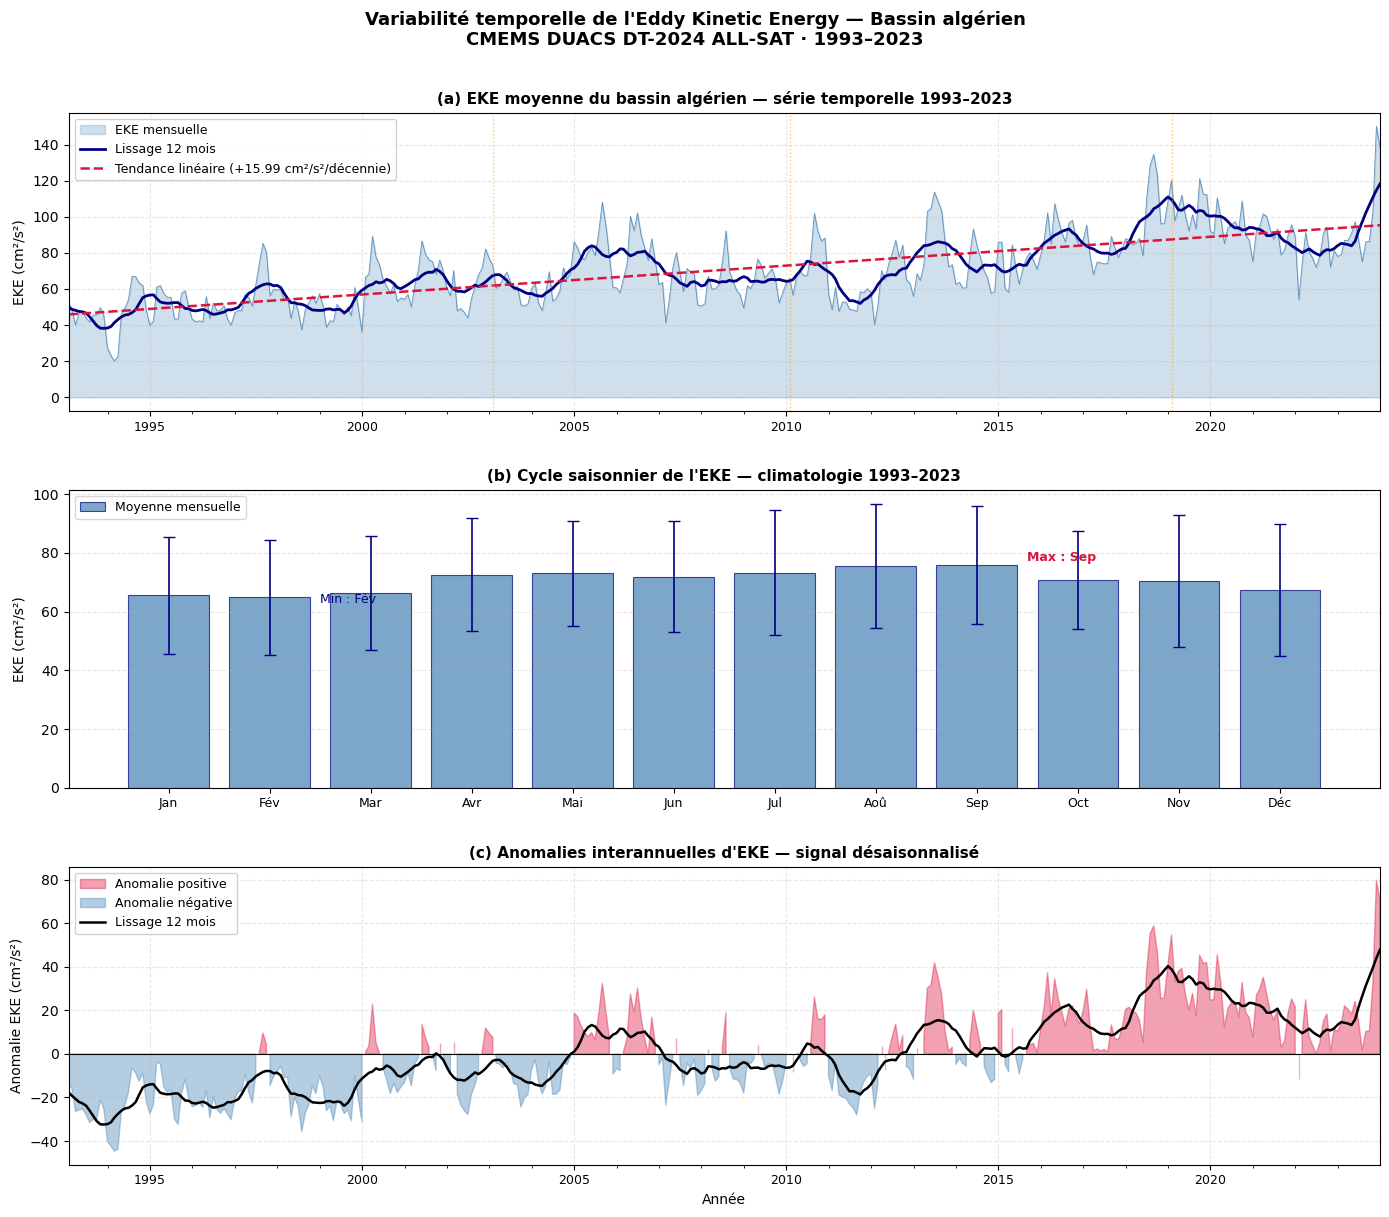


STATISTIQUES EKE — BASSIN ALGÉRIEN 1993–2023
Moyenne globale        : 70.6 cm²/s²
Écart-type             : 20.3 cm²/s²
Maximum observé        : 150.2 cm²/s²
Minimum observé        : 20.1 cm²/s²
Tendance               : +15.99 cm²/s²/décennie
Mois max saisonnier    : Sep
Mois min saisonnier    : Fév


In [9]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
FIG_DIR  = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

# ── Chargement ─────────────────────────────────────────────────────────────
print("Chargement allsat...")
ds = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)

# ── Calcul EKE ─────────────────────────────────────────────────────────────
print("Calcul EKE...")
eke = 0.5 * (ds['ugosa']**2 + ds['vgosa']**2) * 1e4  # cm²/s²

# ── Moyenne spatiale journalière sur le bassin algérien ────────────────────
# On masque les NaN (terre) avant la moyenne spatiale
eke_ts_daily = eke.mean(dim=['latitude', 'longitude'], skipna=True)

# ── Resampling mensuel ─────────────────────────────────────────────────────
print("Resampling mensuel...")
eke_monthly = eke_ts_daily.resample(time='ME').mean()

# ── Cycle saisonnier (climatologie mensuelle) ──────────────────────────────
eke_seasonal = eke_monthly.groupby('time.month').mean()

# ── Anomalie interannuelle (filtre passe-bas 12 mois) ─────────────────────
from scipy.ndimage import uniform_filter1d
eke_smooth = uniform_filter1d(eke_monthly.values, size=12, mode='nearest')

# ── Tendance linéaire ──────────────────────────────────────────────────────
# Sur la série mensuelle
t_num = np.arange(len(eke_monthly))
coeffs = np.polyfit(t_num, eke_monthly.values, 1)
tendance = np.polyval(coeffs, t_num)
slope_per_decade = coeffs[0] * 12 * 10  # cm²/s² par décennie
print(f"Tendance EKE : {slope_per_decade:+.2f} cm²/s² / décennie")

# ── Figure 2 — Série temporelle EKE ───────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.patch.set_facecolor('white')

times_m = eke_monthly.time.values

# ── (a) Série temporelle complète + tendance ───────────────────────────────
ax1 = axes[0]
ax1.fill_between(times_m, eke_monthly.values, alpha=0.25,
                 color='steelblue', label='EKE mensuelle')
ax1.plot(times_m, eke_monthly.values,
         color='steelblue', linewidth=0.6, alpha=0.8)
ax1.plot(times_m, eke_smooth,
         color='navy', linewidth=2.0, label='Lissage 12 mois')
ax1.plot(times_m, tendance,
         color='crimson', linewidth=1.8, linestyle='--',
         label=f'Tendance linéaire ({slope_per_decade:+.2f} cm²/s²/décennie)')

ax1.set_xlim(times_m[0], times_m[-1])
ax1.set_ylabel('EKE (cm²/s²)', fontsize=10)
ax1.set_title('(a) EKE moyenne du bassin algérien — série temporelle 1993–2023',
              fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', fontsize=9, framealpha=0.9)
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.tick_params(axis='x', labelsize=9)

# Annoter les anomalies majeures
for year, label, ypos in [
    ('2003', 'pic 2003', None),
    ('2010', 'pic 2010', None),
    ('2019', 'pic 2019', None),
]:
    idx = np.where(
        (eke_monthly['time.year'].values == int(year)) &
        (eke_monthly['time.month'].values == 1)
    )[0]
    if len(idx) > 0:
        yval = float(eke_monthly.values[idx[0]])
        ax1.axvline(times_m[idx[0]], color='orange',
                    linewidth=1.0, alpha=0.6, linestyle=':')

# ── (b) Cycle saisonnier ───────────────────────────────────────────────────
ax2 = axes[1]
months = np.arange(1, 13)
month_names = ['Jan','Fév','Mar','Avr','Mai','Jun',
               'Jul','Aoû','Sep','Oct','Nov','Déc']

# Écart-type inter-annuel par mois
eke_std_month = eke_monthly.groupby('time.month').std()

ax2.bar(months, eke_seasonal.values,
        color='steelblue', alpha=0.7, edgecolor='navy',
        linewidth=0.8, label='Moyenne mensuelle')
ax2.errorbar(months, eke_seasonal.values, yerr=eke_std_month.values,
             fmt='none', color='navy', capsize=4, linewidth=1.2)

ax2.set_xticks(months)
ax2.set_xticklabels(month_names, fontsize=9)
ax2.set_ylabel('EKE (cm²/s²)', fontsize=10)
ax2.set_title('(b) Cycle saisonnier de l\'EKE — climatologie 1993–2023',
              fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.3, linestyle='--', axis='y')
ax2.legend(fontsize=9)

# Annoter max et min saisonniers
max_m = int(eke_seasonal.values.argmax()) + 1
min_m = int(eke_seasonal.values.argmin()) + 1
ax2.annotate(f'Max : {month_names[max_m-1]}',
             xy=(max_m, eke_seasonal.values.max()),
             xytext=(max_m + 0.5, eke_seasonal.values.max() * 1.02),
             fontsize=9, color='crimson', fontweight='bold')
ax2.annotate(f'Min : {month_names[min_m-1]}',
             xy=(min_m, eke_seasonal.values.min()),
             xytext=(min_m + 0.5, eke_seasonal.values.min() * 0.97),
             fontsize=9, color='navy')

# ── (c) Anomalies interannuelles ───────────────────────────────────────────
ax3 = axes[2]

# Anomalie = EKE mensuelle - climatologie mensuelle correspondante
eke_clim = eke_monthly.groupby('time.month') - eke_seasonal
eke_anom_smooth = uniform_filter1d(eke_clim.values, size=12, mode='nearest')

# Colorer positif/négatif
ax3.fill_between(times_m, eke_clim.values,
                 where=eke_clim.values >= 0,
                 color='crimson', alpha=0.4, label='Anomalie positive')
ax3.fill_between(times_m, eke_clim.values,
                 where=eke_clim.values < 0,
                 color='steelblue', alpha=0.4, label='Anomalie négative')
ax3.plot(times_m, eke_anom_smooth,
         color='black', linewidth=1.8, label='Lissage 12 mois')
ax3.axhline(0, color='black', linewidth=0.8, linestyle='-')

ax3.set_xlim(times_m[0], times_m[-1])
ax3.set_ylabel('Anomalie EKE (cm²/s²)', fontsize=10)
ax3.set_xlabel('Année', fontsize=10)
ax3.set_title('(c) Anomalies interannuelles d\'EKE — signal désaisonnalisé',
              fontsize=11, fontweight='bold')
ax3.legend(loc='upper left', fontsize=9, framealpha=0.9)
ax3.xaxis.set_major_locator(mdates.YearLocator(5))
ax3.xaxis.set_minor_locator(mdates.YearLocator(1))
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax3.grid(True, alpha=0.3, linestyle='--')
ax3.tick_params(axis='x', labelsize=9)

# ── Titre général ──────────────────────────────────────────────────────────
fig.suptitle(
    'Variabilité temporelle de l\'Eddy Kinetic Energy — Bassin algérien\n'
    'CMEMS DUACS DT-2024 ALL-SAT · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)

plt.tight_layout(h_pad=2.5)

# ── Sauvegarde ─────────────────────────────────────────────────────────────
OUTPUT = FIG_DIR + r"\Fig02_EKE_serie_temporelle_1993_2023.png"
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"Figure sauvegardée → {OUTPUT}")
plt.show()

# ── Statistiques clés pour la rédaction ───────────────────────────────────
print("\n" + "=" * 55)
print("STATISTIQUES EKE — BASSIN ALGÉRIEN 1993–2023")
print("=" * 55)
print(f"Moyenne globale        : {float(eke_monthly.mean()):.1f} cm²/s²")
print(f"Écart-type             : {float(eke_monthly.std()):.1f} cm²/s²")
print(f"Maximum observé        : {float(eke_monthly.max()):.1f} cm²/s²")
print(f"Minimum observé        : {float(eke_monthly.min()):.1f} cm²/s²")
print(f"Tendance               : {slope_per_decade:+.2f} cm²/s²/décennie")
max_month_idx = int(eke_seasonal.values.argmax())
min_month_idx = int(eke_seasonal.values.argmin())
print(f"Mois max saisonnier    : {month_names[max_month_idx]}")
print(f"Mois min saisonnier    : {month_names[min_month_idx]}")
print("=" * 55)

ds.close()

Chargement TWO-SAT...
Variables disponibles : ['adt', 'sla', 'ugos', 'vgos', 'tpa_correction']
Calcul EKE TWO-SAT (anomalies calculées manuellement)...
EKE calculée.
Resampling mensuel...

Test de Mann-Kendall...
  EKE brute    : tendance=increasing, p=0.0044, slope=0.0172 cm²/s²/mois
  EKE anomalie : tendance=increasing, p=0.0065
  Pente de Sen : +2.06 cm²/s²/décennie
  Significatif : True

Analyse Wavelet Morlet...

Figure sauvegardée → C:\Users\kikk\CLAUDE ARTICLE DATA\FIGURES\Fig03_MannKendall_Wavelet_EKE_1993_2023.png


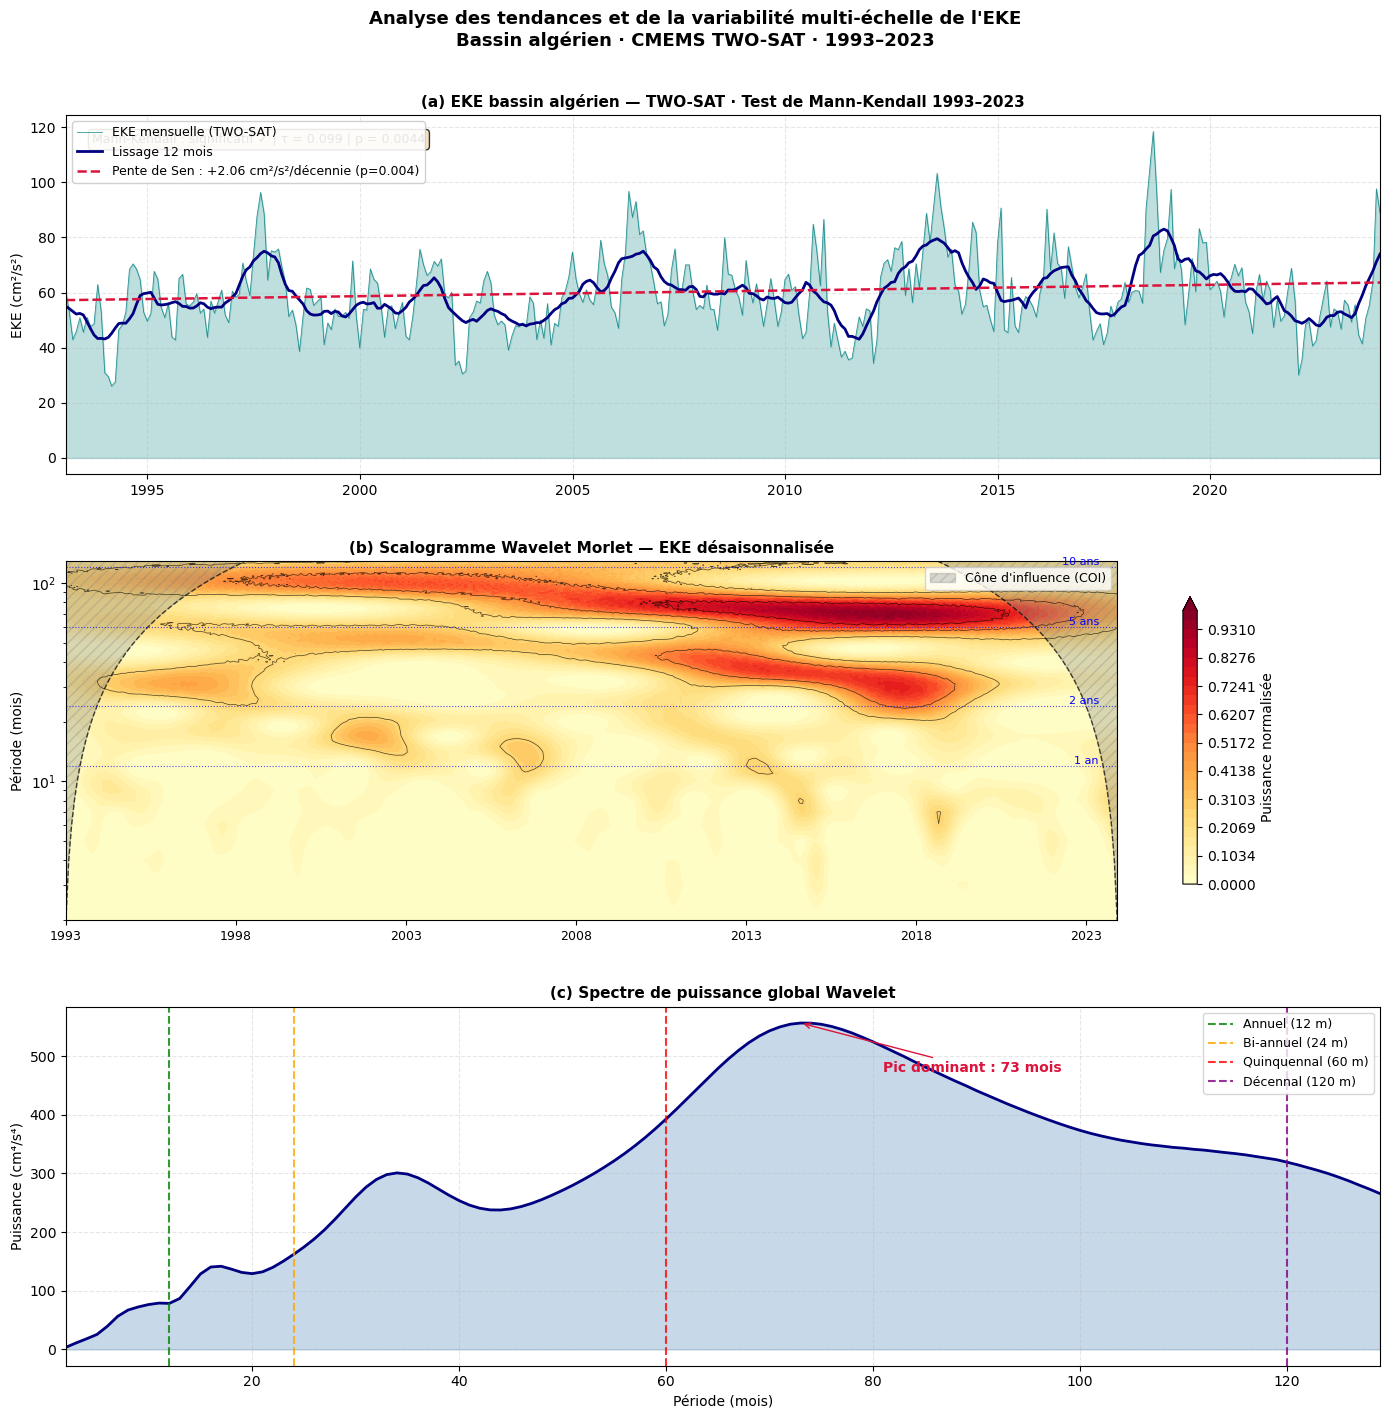


RÉSULTATS MANN-KENDALL — BASSIN ALGÉRIEN
Tendance               : increasing
Tau de Kendall         : 0.0989
p-value                : 0.004411
Pente de Sen           : +2.0640 cm²/s²/décennie
Significatif (p<0.05)  : True
Pic Wavelet dominant   : 73 mois


In [17]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pymannkendall as mk
import pywt
import os
import warnings
from scipy.ndimage import uniform_filter1d
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
FIG_DIR  = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

# ── Chargement TWO-SAT ────────────────────────────────────────────────────
print("Chargement TWO-SAT...")
ds2 = xr.open_dataset(
    DATA_DIR + r"\c3s_obs-sl_glo_phy-ssh_my_twosat-l4-duacs-0.25deg"
               r"_P1D_multi-vars_4.88W-9.88E_35.12N-40.88N_1993-01-01-2023-12-31.nc"
)

# ── Vérification des variables disponibles ────────────────────────────────
print(f"Variables disponibles : {list(ds2.data_vars)}")

# ── EKE sur TWO-SAT ───────────────────────────────────────────────────────
# TWO-SAT n'a pas ugosa/vgosa → on calcule les anomalies manuellement
# ugosa = ugos - moyenne_temporelle(ugos)
print("Calcul EKE TWO-SAT (anomalies calculées manuellement)...")
ugos_mean_time = ds2['ugos'].mean('time')
vgos_mean_time = ds2['vgos'].mean('time')
ugosa2 = ds2['ugos'] - ugos_mean_time   # anomalie géostrophique
vgosa2 = ds2['vgos'] - vgos_mean_time

eke2 = 0.5 * (ugosa2**2 + vgosa2**2) * 1e4   # cm²/s²
print("EKE calculée.")

# ── Moyenne spatiale + resampling mensuel ─────────────────────────────────
print("Resampling mensuel...")
eke2_daily   = eke2.mean(dim=['latitude', 'longitude'], skipna=True)
eke2_monthly = eke2_daily.resample(time='ME').mean()

# ── Climatologie et anomalie désaisonnalisée ──────────────────────────────
eke2_clim = eke2_monthly.groupby('time.month').mean()
eke2_anom = eke2_monthly.groupby('time.month') - eke2_clim

vals    = eke2_monthly.values
vals_an = eke2_anom.values
times_m = eke2_monthly.time.values
N       = len(vals)

# ── MANN-KENDALL ──────────────────────────────────────────────────────────
print("\nTest de Mann-Kendall...")
result_mk    = mk.original_test(vals)
result_mk_an = mk.original_test(vals_an)

slope_decade = result_mk.slope * 12 * 10
print(f"  EKE brute    : tendance={result_mk.trend}, "
      f"p={result_mk.p:.4f}, slope={result_mk.slope:.4f} cm²/s²/mois")
print(f"  EKE anomalie : tendance={result_mk_an.trend}, "
      f"p={result_mk_an.p:.4f}")
print(f"  Pente de Sen : {slope_decade:+.2f} cm²/s²/décennie")
print(f"  Significatif : {result_mk.p < 0.05}")

# ── ANALYSE WAVELET (Morlet) ──────────────────────────────────────────────
print("\nAnalyse Wavelet Morlet...")
signal = vals_an - np.nanmean(vals_an)
signal = np.where(np.isnan(signal), 0, signal)
dt     = 1.0   # mois

scales  = np.arange(2, 130)
freqs   = pywt.scale2frequency('cmor1.5-1.0', scales) / dt
periods = 1.0 / freqs   # mois

coeffs, _ = pywt.cwt(signal, scales, 'cmor1.5-1.0', sampling_period=dt)
power     = np.abs(coeffs)**2
coi       = np.minimum(np.arange(1, N + 1), np.arange(N, 0, -1)) * dt * 2

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 3
# ═══════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(14, 14))
fig.patch.set_facecolor('white')

# ── (a) EKE TWO-SAT + Mann-Kendall ────────────────────────────────────────
ax1 = fig.add_subplot(3, 1, 1)

smooth     = uniform_filter1d(vals, size=12, mode='nearest')
t_num      = np.arange(N)
trend_line = result_mk.slope * t_num + np.nanmedian(vals)

ax1.fill_between(times_m, vals, alpha=0.25, color='teal')
ax1.plot(times_m, vals,       color='teal',    linewidth=0.6,
         alpha=0.8, label='EKE mensuelle (TWO-SAT)')
ax1.plot(times_m, smooth,     color='navy',    linewidth=2.0,
         label='Lissage 12 mois')
ax1.plot(times_m, trend_line, color='crimson', linewidth=1.8,
         linestyle='--',
         label=f"Pente de Sen : {slope_decade:+.2f} cm²/s²/décennie "
               f"(p={'<0.001' if result_mk.p < 0.001 else f'{result_mk.p:.3f}'})")

ax1.set_xlim(times_m[0], times_m[-1])
ax1.set_ylabel('EKE (cm²/s²)', fontsize=10)
ax1.set_title('(a) EKE bassin algérien — TWO-SAT · Test de Mann-Kendall 1993–2023',
              fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', fontsize=9, framealpha=0.9)
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, alpha=0.3, linestyle='--')

sig_txt = (f"Mann-Kendall : {'significatif ✓' if result_mk.p < 0.05 else 'non significatif'} "
           f"| τ = {result_mk.Tau:.3f} | p = {result_mk.p:.4f}")
ax1.text(0.02, 0.95, sig_txt, transform=ax1.transAxes,
         fontsize=9, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# ── (b) Scalogramme Wavelet ────────────────────────────────────────────────
ax2 = fig.add_subplot(3, 1, 2)

t_idx      = np.arange(N)
power_norm = power / power.max()

cf2 = ax2.contourf(t_idx, periods, power_norm,
                   levels=np.linspace(0, 1, 30),
                   cmap='YlOrRd', extend='max')
ax2.contour(t_idx, periods, power_norm,
            levels=[0.25, 0.5, 0.75],
            colors='black', linewidths=0.5, alpha=0.7)
ax2.fill_between(t_idx, coi, periods.max(),
                 alpha=0.3, color='gray', hatch='///',
                 label="Cône d'influence (COI)")
ax2.plot(t_idx, coi, 'k--', linewidth=1.0, alpha=0.7)

for p_ref, lbl in [(12,'1 an'),(24,'2 ans'),(60,'5 ans'),(120,'10 ans')]:
    if p_ref <= periods.max():
        ax2.axhline(p_ref, color='blue', linewidth=0.8,
                    linestyle=':', alpha=0.7)
        ax2.text(N * 0.98, p_ref, lbl,
                 ha='right', va='bottom', fontsize=8, color='blue')

year_ticks  = np.arange(0, N, 60)
year_labels = [str(1993 + i // 12) for i in year_ticks]
ax2.set_xticks(year_ticks)
ax2.set_xticklabels(year_labels, fontsize=9)
ax2.set_yscale('log')
ax2.set_ylim(2, min(130, periods.max()))
ax2.set_ylabel('Période (mois)', fontsize=10)
ax2.set_title('(b) Scalogramme Wavelet Morlet — EKE désaisonnalisée',
              fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
plt.colorbar(cf2, ax=ax2, label='Puissance normalisée', shrink=0.8)

# ── (c) Spectre de puissance global ───────────────────────────────────────
ax3 = fig.add_subplot(3, 1, 3)

global_power = np.nanmean(power, axis=1)
ax3.plot(periods, global_power, color='navy', linewidth=2.0)
ax3.fill_between(periods, global_power, alpha=0.3, color='steelblue')

for p_ref, c_ref, l_ref in zip(
        [12,   24,          60,             120],
        ['green','orange','red',         'purple'],
        ['Annuel (12 m)','Bi-annuel (24 m)',
         'Quinquennal (60 m)','Décennal (120 m)']
):
    if p_ref <= periods.max():
        ax3.axvline(p_ref, color=c_ref, linewidth=1.5,
                    linestyle='--', alpha=0.8, label=l_ref)

peak_idx = np.argmax(global_power)
ax3.annotate(f'Pic dominant : {periods[peak_idx]:.0f} mois',
             xy=(periods[peak_idx], global_power[peak_idx]),
             xytext=(periods[peak_idx] + 8,
                     global_power[peak_idx] * 0.85),
             arrowprops=dict(arrowstyle='->', color='crimson'),
             fontsize=10, color='crimson', fontweight='bold')

ax3.set_xlim(2, min(130, periods.max()))
ax3.set_xlabel('Période (mois)', fontsize=10)
ax3.set_ylabel('Puissance (cm⁴/s⁴)', fontsize=10)
ax3.set_title('(c) Spectre de puissance global Wavelet',
              fontsize=11, fontweight='bold')
ax3.legend(fontsize=9, loc='upper right')
ax3.grid(True, alpha=0.3, linestyle='--')

# ── Titre général ──────────────────────────────────────────────────────────
fig.suptitle(
    "Analyse des tendances et de la variabilité multi-échelle de l'EKE\n"
    'Bassin algérien · CMEMS TWO-SAT · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(h_pad=3)

# ── Sauvegarde ─────────────────────────────────────────────────────────────
OUTPUT = FIG_DIR + r"\Fig03_MannKendall_Wavelet_EKE_1993_2023.png"
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"\nFigure sauvegardée → {OUTPUT}")
plt.show()

# ── Résumé ─────────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("RÉSULTATS MANN-KENDALL — BASSIN ALGÉRIEN")
print("=" * 55)
print(f"Tendance               : {result_mk.trend}")
print(f"Tau de Kendall         : {result_mk.Tau:.4f}")
print(f"p-value                : {result_mk.p:.6f}")
print(f"Pente de Sen           : {slope_decade:+.4f} cm²/s²/décennie")
print(f"Significatif (p<0.05)  : {result_mk.p < 0.05}")
print(f"Pic Wavelet dominant   : {periods[peak_idx]:.0f} mois")
print("=" * 55)

ds2.close()

Chargement SLA allsat...
Resampling mensuel SLA...
Dimensions SLA pour EOF : (372, 48, 120)
Calcul EOF (4 modes)...
Variance expliquée par mode :
  EOF1 : 54.2%
  EOF2 : 5.0%
  EOF3 : 3.6%
  EOF4 : 3.4%

Figure sauvegardée → C:\Users\kikk\CLAUDE ARTICLE DATA\FIGURES\Fig04_EOF_SLA_1993_2023.png


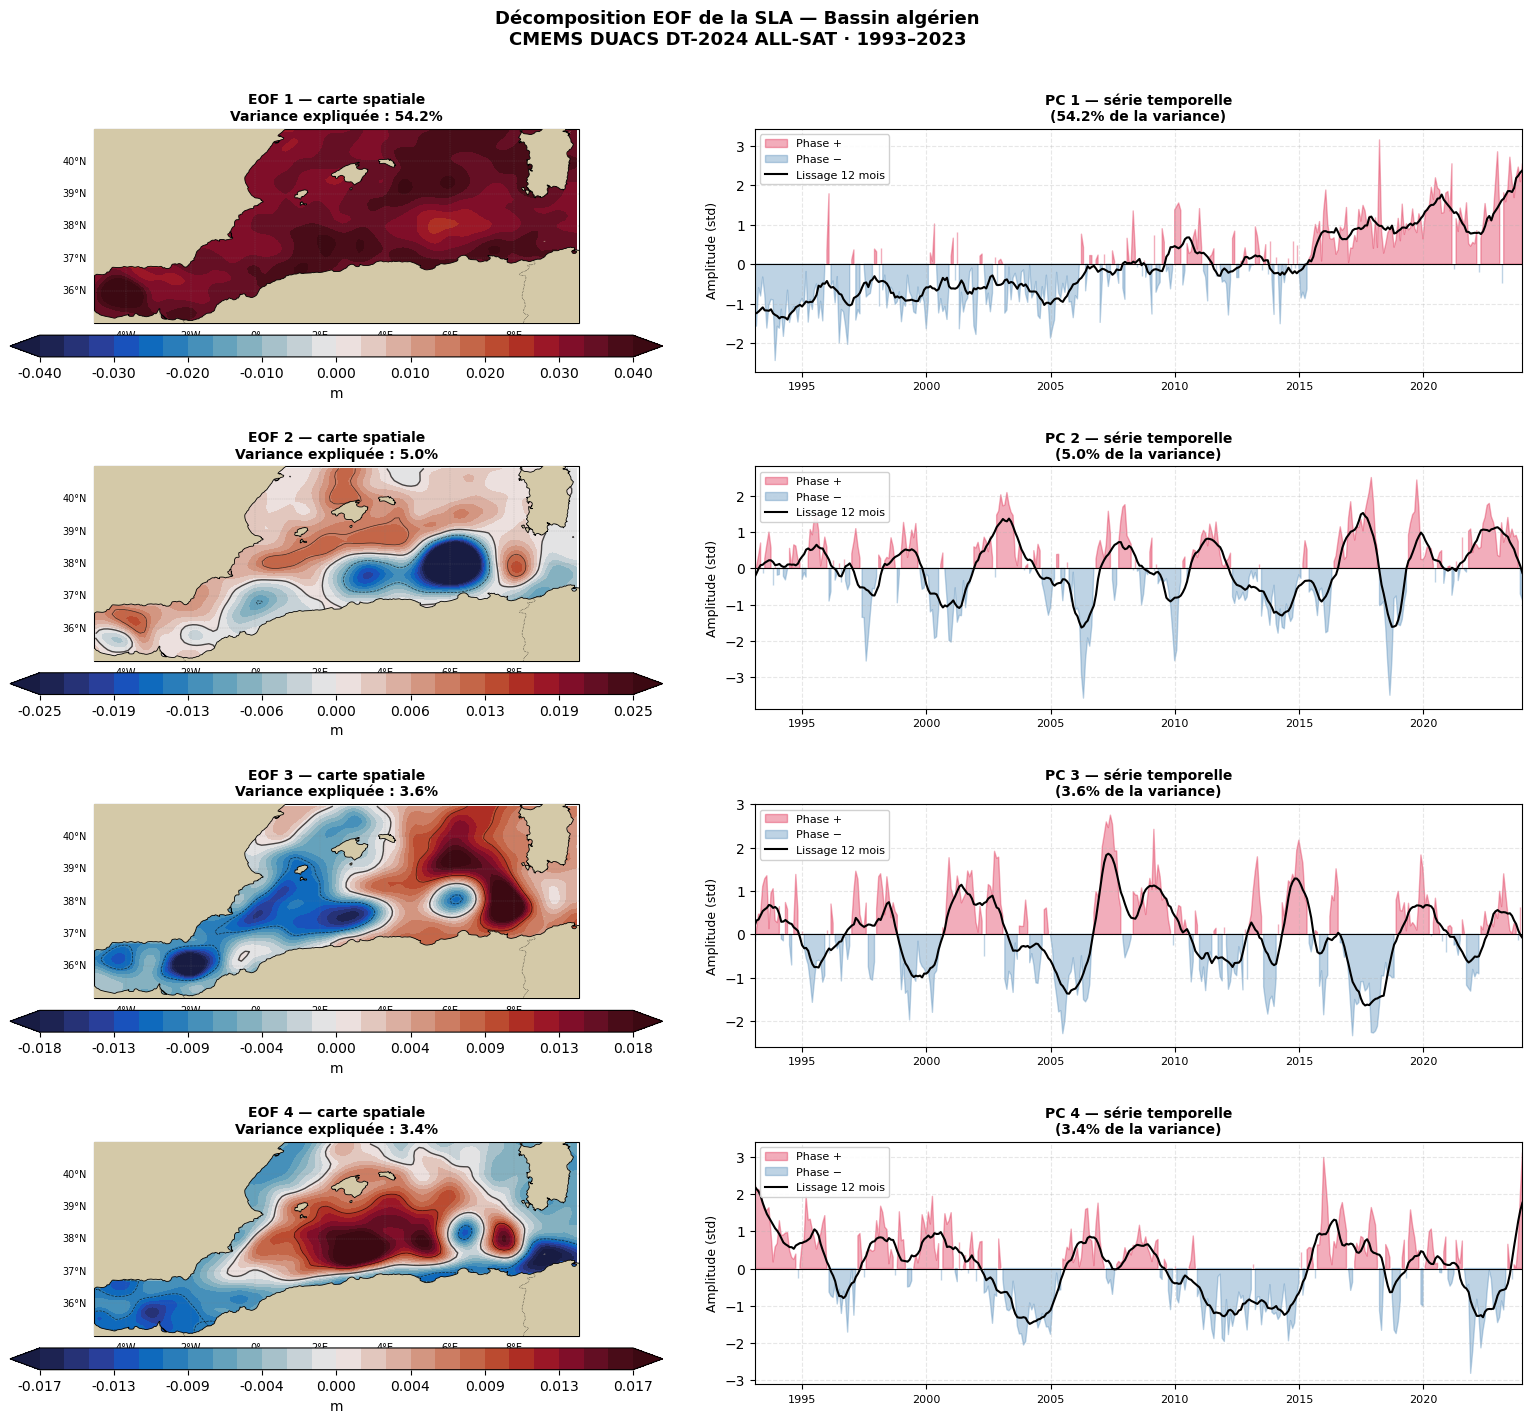


RÉSULTATS EOF — SLA BASSIN ALGÉRIEN
  EOF1 : 54.25% de variance
  EOF2 : 4.97% de variance
  EOF3 : 3.65% de variance
  EOF4 : 3.39% de variance
  Total  : 66.2%


In [24]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from eofs.xarray import Eof
import os
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
FIG_DIR  = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

# ── Chargement ─────────────────────────────────────────────────────────────
print("Chargement SLA allsat...")
ds = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)

# ── Préparation SLA mensuelle ──────────────────────────────────────────────
print("Resampling mensuel SLA...")
sla_monthly = ds['sla'].resample(time='ME').mean()

# Anomalie mensuelle (retirer la climatologie mensuelle)
sla_clim    = sla_monthly.groupby('time.month').mean()
sla_anom    = sla_monthly.groupby('time.month') - sla_clim

# Remplir les NaN (terre) par 0 pour l'EOF
sla_filled  = sla_anom.fillna(0.0)

print(f"Dimensions SLA pour EOF : {sla_filled.shape}")
# (time, latitude, longitude)

# ── CALCUL EOF ─────────────────────────────────────────────────────────────
print("Calcul EOF (4 modes)...")
solver = Eof(sla_filled, weights=None)

n_modes = 4
eofs    = solver.eofsAsCovariance(neofs=n_modes)    # cartes spatiales
pcs     = solver.pcs(npcs=n_modes, pcscaling=1)     # séries temporelles
var_frac = solver.varianceFraction()   # variance expliquée
var_frac = var_frac[:n_modes] 
print("Variance expliquée par mode :")
for i in range(n_modes):
    print(f"  EOF{i+1} : {float(var_frac[i])*100:.1f}%")

# ── FIGURE 4 ───────────────────────────────────────────────────────────────
proj = ccrs.PlateCarree()
lon_min, lon_max = -5, 10
lat_min, lat_max = 35, 41
LAND_COLOR = '#d4c9a8'

fig = plt.figure(figsize=(16, 14))
fig.patch.set_facecolor('white')

import matplotlib.dates as mdates

for mode in range(n_modes):
    var_pct = float(var_frac[mode]) * 100

    # ── Carte spatiale EOF ─────────────────────────────────────────────────
    ax_map = fig.add_subplot(n_modes, 2, mode * 2 + 1, projection=proj)
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)

    eof_data = eofs.isel(mode=mode)
    vmax     = float(np.nanpercentile(np.abs(eof_data.values), 98))

    cf = ax_map.contourf(
        eof_data.longitude, eof_data.latitude, eof_data.values,
        levels=np.linspace(-vmax, vmax, 25),
        cmap=cmocean.cm.balance, transform=proj, extend='both'
    )
    ax_map.contour(
        eof_data.longitude, eof_data.latitude, eof_data.values,
        levels=[-0.01, 0, 0.01], colors='black',
        linewidths=[0.5, 1.0, 0.5], alpha=0.7, transform=proj
    )
    ax_map.add_feature(cfeature.LAND,      facecolor=LAND_COLOR, zorder=5)
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.6,         zorder=6)
    ax_map.add_feature(cfeature.BORDERS,   linewidth=0.4,
                        linestyle=':', zorder=6)
    gl = ax_map.gridlines(draw_labels=True, linewidth=0.3,
                          color='gray', alpha=0.4, linestyle='--')
    gl.top_labels   = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 7}
    gl.ylabel_style = {'size': 7}

    plt.colorbar(cf, ax=ax_map, orientation='horizontal',
                 pad=0.05, shrink=0.85, label='m', aspect=30,
                 format='%.3f')
    ax_map.set_title(
        f'EOF {mode+1} — carte spatiale\n'
        f'Variance expliquée : {var_pct:.1f}%',
        fontsize=10, fontweight='bold'
    )

    # ── Série temporelle PC ────────────────────────────────────────────────
    ax_pc = fig.add_subplot(n_modes, 2, mode * 2 + 2)
    pc_vals = pcs.isel(mode=mode).values
    times   = pcs.time.values

    from scipy.ndimage import uniform_filter1d
    pc_smooth = uniform_filter1d(pc_vals, size=12, mode='nearest')

    ax_pc.fill_between(times, pc_vals,
                       where=pc_vals >= 0,
                       color='crimson', alpha=0.35, label='Phase +')
    ax_pc.fill_between(times, pc_vals,
                       where=pc_vals < 0,
                       color='steelblue', alpha=0.35, label='Phase −')
    ax_pc.plot(times, pc_smooth,
               color='black', linewidth=1.5, label='Lissage 12 mois')
    ax_pc.axhline(0, color='black', linewidth=0.8)

    ax_pc.set_xlim(times[0], times[-1])
    ax_pc.set_ylabel('Amplitude (std)', fontsize=9)
    ax_pc.set_title(
        f'PC {mode+1} — série temporelle\n'
        f'({var_pct:.1f}% de la variance)',
        fontsize=10, fontweight='bold'
    )
    ax_pc.legend(loc='upper left', fontsize=8, framealpha=0.9)
    ax_pc.xaxis.set_major_locator(mdates.YearLocator(5))
    ax_pc.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax_pc.grid(True, alpha=0.3, linestyle='--')
    ax_pc.tick_params(axis='x', labelsize=8)

# ── Titre général ──────────────────────────────────────────────────────────
fig.suptitle(
    'Décomposition EOF de la SLA — Bassin algérien\n'
    'CMEMS DUACS DT-2024 ALL-SAT · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(h_pad=2.5, w_pad=2)

# ── Sauvegarde ─────────────────────────────────────────────────────────────
OUTPUT = FIG_DIR + r"\Fig04_EOF_SLA_1993_2023.png"
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"\nFigure sauvegardée → {OUTPUT}")
plt.show()

# ── Résumé ─────────────────────────────────────────────────────────────────
print("\n" + "=" * 50)
print("RÉSULTATS EOF — SLA BASSIN ALGÉRIEN")
print("=" * 50)
for i in range(n_modes):
    print(f"  EOF{i+1} : {float(var_frac[i])*100:.2f}% de variance")
print(f"  Total  : {float(var_frac.sum())*100:.1f}%")
print("=" * 50)

ds.close()

Chargement MEDSEA PHY courants...
Dimensions du fichier : {'time': 11322, 'depth': 1, 'latitude': 144, 'longitude': 361}
Variables : ['uo', 'vo']
Calcul des moyennes annuelles...
Forme u_mean après squeeze : (144, 361)
Calcul divergence ∇·u...
Préparation matrice features pour CAH...
Pixels valides (mer) : 27359 / 51984
Recherche du nombre optimal de clusters...
  N=3 : CH=9442.7
  N=4 : CH=10527.2
  N=5 : CH=10965.6
  N=6 : CH=11056.1
  N=7 : CH=11594.3
  N=8 : CH=11598.1

Nombre optimal de clusters : 8

Profils par cluster :
  Cluster 1 : N=  563 | U=+0.2663 m/s | V=+0.1178 m/s | Speed=0.2933 m/s | ∇·u=+nan → CONVERGENCE
  Cluster 2 : N= 2949 | U=+0.0956 m/s | V=+0.0717 m/s | Speed=0.1264 m/s | ∇·u=+nan → CONVERGENCE
  Cluster 3 : N= 1308 | U=+0.2054 m/s | V=-0.0384 m/s | Speed=0.2145 m/s | ∇·u=+nan → CONVERGENCE
  Cluster 4 : N= 8748 | U=+0.0623 m/s | V=-0.0044 m/s | Speed=0.0675 m/s | ∇·u=+nan → CONVERGENCE
  Cluster 5 : N= 3020 | U=-0.0631 m/s | V=+0.0109 m/s | Speed=0.0697 m/s | 

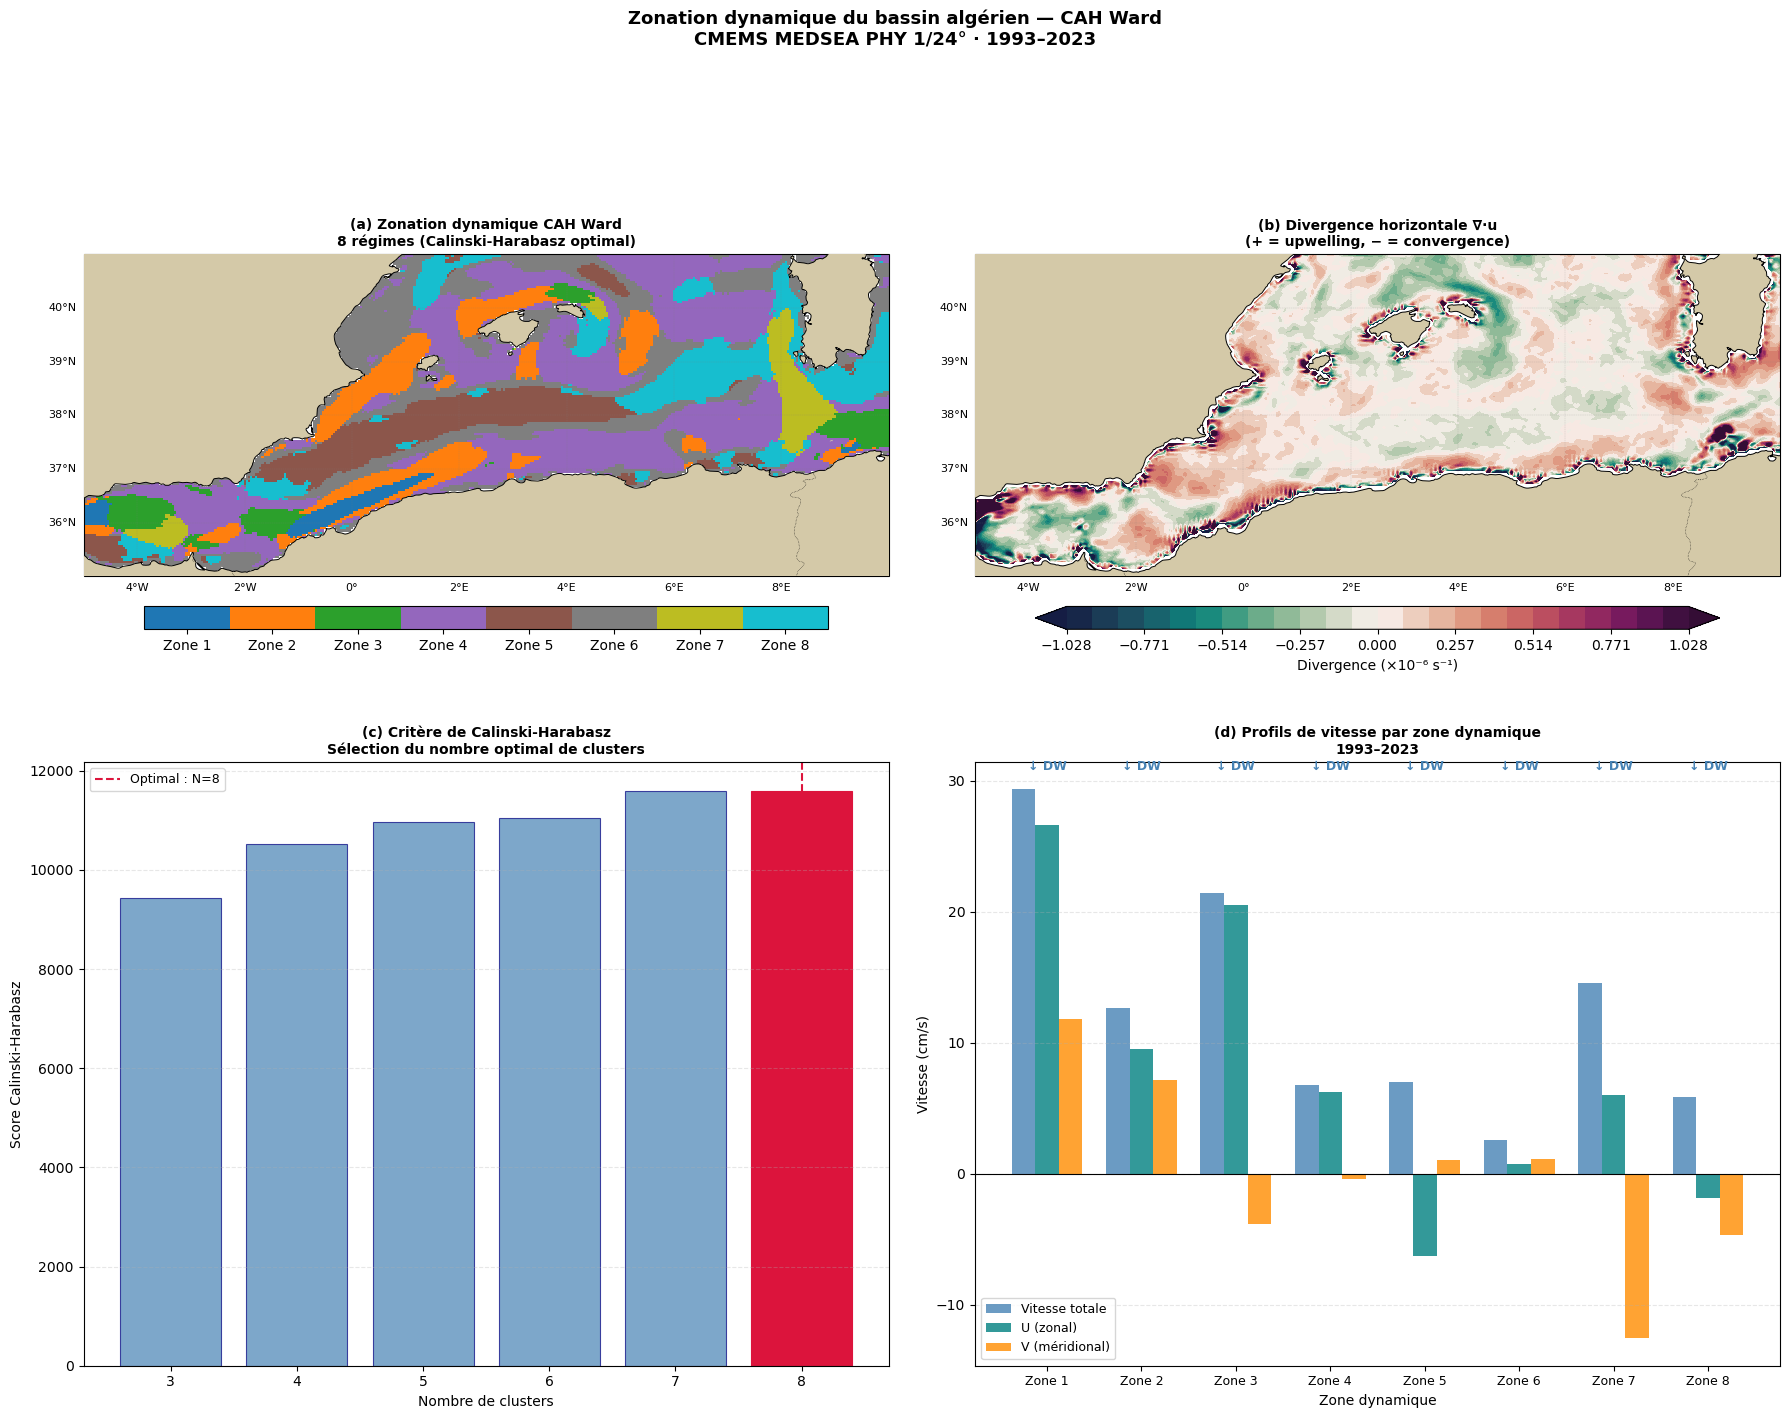

In [28]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import calinski_harabasz_score
from sklearn.preprocessing import StandardScaler
import os, warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
FIG_DIR  = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

# ── Chargement ────────────────────────────────────────────────────────────
print("Chargement MEDSEA PHY courants...")
ds_cur = xr.open_dataset(
    DATA_DIR + r"\cmems_mod_med_phy-cur_my_4.2km_P1D-m_uo-vo"
               r"_5.00W-10.00E_35.02N-40.98N_1.02m_1993-01-01-2023-12-31.nc"
)
print(f"Dimensions du fichier : {dict(ds_cur.dims)}")
print(f"Variables : {list(ds_cur.data_vars)}")

# ── Moyenne temporelle + squeeze (supprime dimension depth=1) ─────────────
print("Calcul des moyennes annuelles...")
u_mean = ds_cur['uo'].mean('time').squeeze().values   # ← .squeeze() ici
v_mean = ds_cur['vo'].mean('time').squeeze().values   # ← .squeeze() ici

print(f"Forme u_mean après squeeze : {u_mean.shape}")   # doit être (lat, lon)

lats = ds_cur['latitude'].values
lons = ds_cur['longitude'].values

# ── Divergence ∇·u ────────────────────────────────────────────────────────
print("Calcul divergence ∇·u...")
dlat_m = np.abs(np.diff(lats).mean()) * 111000
dlon_m = np.abs(np.diff(lons).mean()) * 111000 * \
         np.cos(np.radians(np.mean(lats)))

du_dx = np.gradient(u_mean, dlon_m, axis=1)
dv_dy = np.gradient(v_mean, dlat_m, axis=0)
div   = du_dx + dv_dy

# ── Préparation CAH ───────────────────────────────────────────────────────
print("Préparation matrice features pour CAH...")
nlat, nlon   = u_mean.shape
mask_valid   = ~(np.isnan(u_mean) | np.isnan(v_mean))
print(f"Pixels valides (mer) : {mask_valid.sum()} / {nlat * nlon}")

u_flat = u_mean[mask_valid]
v_flat = v_mean[mask_valid]

X      = np.column_stack([u_flat, v_flat])
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

# ── Calinski-Harabasz ─────────────────────────────────────────────────────
print("Recherche du nombre optimal de clusters...")
Z = linkage(X_norm, method='ward')

ch_scores = {}
for n in range(3, 9):
    labels_test  = fcluster(Z, t=n, criterion='maxclust')
    ch_scores[n] = calinski_harabasz_score(X_norm, labels_test)
    print(f"  N={n} : CH={ch_scores[n]:.1f}")

n_optimal   = max(ch_scores, key=ch_scores.get)
print(f"\nNombre optimal de clusters : {n_optimal}")

# ── CAH finale ────────────────────────────────────────────────────────────
labels_flat = fcluster(Z, t=n_optimal, criterion='maxclust')
labels_2d   = np.full((nlat, nlon), np.nan)
labels_2d[mask_valid] = labels_flat

# ── Profils par cluster ───────────────────────────────────────────────────
print("\nProfils par cluster :")
cluster_stats = {}
for c in range(1, n_optimal + 1):
    mask_c = labels_flat == c
    u_c    = u_flat[mask_c]
    v_c    = v_flat[mask_c]
    speed  = np.sqrt(u_c**2 + v_c**2)
    div_c  = div[mask_valid][mask_c]
    cluster_stats[c] = {
        'n':      mask_c.sum(),
        'u_mean': u_c.mean(),
        'v_mean': v_c.mean(),
        'speed':  speed.mean(),
        'div':    div_c.mean(),
    }
    regime = "UPWELLING" if div_c.mean() > 0 else "CONVERGENCE"
    print(f"  Cluster {c} : N={mask_c.sum():5d} | "
          f"U={u_c.mean():+.4f} m/s | V={v_c.mean():+.4f} m/s | "
          f"Speed={speed.mean():.4f} m/s | ∇·u={div_c.mean():+.2e} → {regime}")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 5
# ═══════════════════════════════════════════════════════════════════════════
proj       = ccrs.PlateCarree()
LAND_COLOR = '#d4c9a8'
cmap_cah   = plt.cm.get_cmap('tab10', n_optimal)

fig = plt.figure(figsize=(18, 14))
fig.patch.set_facecolor('white')

def add_geo(ax):
    ax.add_feature(cfeature.LAND,      facecolor=LAND_COLOR, zorder=5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.7,         zorder=6)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', zorder=6)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                      color='gray', alpha=0.4, linestyle='--')
    gl.top_labels   = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# ── (a) Carte zonation CAH ────────────────────────────────────────────────
ax1 = fig.add_subplot(2, 2, 1, projection=proj)
ax1.set_extent([-5, 10, 35, 41], crs=proj)

im1 = ax1.pcolormesh(
    lons, lats, labels_2d,
    cmap=cmap_cah, vmin=0.5, vmax=n_optimal + 0.5,
    transform=proj
)
add_geo(ax1)
cb1 = plt.colorbar(im1, ax=ax1, orientation='horizontal',
                   pad=0.05, shrink=0.85, aspect=30)
cb1.set_ticks(range(1, n_optimal + 1))
cb1.set_ticklabels([f'Zone {c}' for c in range(1, n_optimal + 1)])
ax1.set_title(f'(a) Zonation dynamique CAH Ward\n'
              f'{n_optimal} régimes (Calinski-Harabasz optimal)',
              fontsize=10, fontweight='bold')

# ── (b) Carte divergence ─────────────────────────────────────────────────
ax2 = fig.add_subplot(2, 2, 2, projection=proj)
ax2.set_extent([-5, 10, 35, 41], crs=proj)

div_plot = np.where(mask_valid, div, np.nan)
vmax_div = np.nanpercentile(np.abs(div_plot), 97)

cf2 = ax2.contourf(
    lons, lats, div_plot * 1e6,
    levels=np.linspace(-vmax_div * 1e6, vmax_div * 1e6, 25),
    cmap=cmocean.cm.curl, transform=proj, extend='both'
)
add_geo(ax2)
plt.colorbar(cf2, ax=ax2, orientation='horizontal',
             pad=0.05, shrink=0.85,
             label='Divergence (×10⁻⁶ s⁻¹)', aspect=30)
ax2.set_title('(b) Divergence horizontale ∇·u\n'
              '(+ = upwelling, − = convergence)',
              fontsize=10, fontweight='bold')

# ── (c) Calinski-Harabasz ─────────────────────────────────────────────────
ax3 = fig.add_subplot(2, 2, 3)
ns   = list(ch_scores.keys())
chs  = list(ch_scores.values())
bars = ax3.bar(ns, chs, color='steelblue', alpha=0.7,
               edgecolor='navy', linewidth=0.8)
bars[n_optimal - min(ns)].set_color('crimson')
bars[n_optimal - min(ns)].set_alpha(1.0)
ax3.axvline(n_optimal, color='crimson', linewidth=1.5,
            linestyle='--', label=f'Optimal : N={n_optimal}')
ax3.set_xlabel('Nombre de clusters', fontsize=10)
ax3.set_ylabel('Score Calinski-Harabasz',  fontsize=10)
ax3.set_title('(c) Critère de Calinski-Harabasz\n'
              'Sélection du nombre optimal de clusters',
              fontsize=10, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3, linestyle='--', axis='y')
ax3.set_xticks(ns)

# ── (d) Profils de vitesse par cluster ───────────────────────────────────
ax4 = fig.add_subplot(2, 2, 4)
clusters = list(cluster_stats.keys())
speeds   = [cluster_stats[c]['speed']  * 100 for c in clusters]
u_vals   = [cluster_stats[c]['u_mean'] * 100 for c in clusters]
v_vals   = [cluster_stats[c]['v_mean'] * 100 for c in clusters]

x     = np.arange(len(clusters))
width = 0.25

ax4.bar(x - width, speeds,  width, label='Vitesse totale',
        color='steelblue', alpha=0.8)
ax4.bar(x,          u_vals, width, label='U (zonal)',
        color='teal',        alpha=0.8)
ax4.bar(x + width,  v_vals, width, label='V (méridional)',
        color='darkorange',  alpha=0.8)

ax4.set_xlabel('Zone dynamique', fontsize=10)
ax4.set_ylabel('Vitesse (cm/s)', fontsize=10)
ax4.set_title('(d) Profils de vitesse par zone dynamique\n'
              '1993–2023', fontsize=10, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels([f'Zone {c}' for c in clusters], fontsize=9)
ax4.legend(fontsize=9)
ax4.axhline(0, color='black', linewidth=0.8)
ax4.grid(True, alpha=0.3, linestyle='--', axis='y')

# Annoter upwelling/downwelling
for i, c in enumerate(clusters):
    dv  = cluster_stats[c]['div'] * 1e6
    txt = '↑ UP' if dv > 0 else '↓ DW'
    col = 'crimson' if dv > 0 else 'steelblue'
    ymax = max(max(speeds), max(u_vals), max(v_vals)) * 1.05
    ax4.text(i, ymax, txt, ha='center', fontsize=9,
             color=col, fontweight='bold')

# ── Titre général ─────────────────────────────────────────────────────────
fig.suptitle(
    'Zonation dynamique du bassin algérien — CAH Ward\n'
    'CMEMS MEDSEA PHY 1/24° · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(h_pad=3, w_pad=2)

OUTPUT = FIG_DIR + r"\Fig05_CAH_zonation_1993_2023.png"
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"\nFigure sauvegardée → {OUTPUT}")
plt.show()

ds_cur.close()

Chargement MEDSEA PHY courants...
Calcul des moyennes annuelles...
Forme après squeeze : (144, 361)
Calcul divergence ∇·u...
Préparation matrice features pour CAH...
Pixels valides (mer) : 27359 / 51984
Recherche du nombre optimal de clusters (N=3 à 6)...
  N=3 : CH=9442.7
  N=4 : CH=10527.2
  N=5 : CH=10965.6
  N=6 : CH=11056.1

Nombre optimal de clusters : 6

Profils par cluster :
  Zone 1 : N= 3512 px | U=+0.1229 m/s | V=+0.0791 m/s | Speed=0.1531 m/s | ∇·u=+1.175e-08 s⁻¹ → UPWELLING ↑ (NaN div: 0.0%)
  Zone 2 : N= 1308 px | U=+0.2054 m/s | V=-0.0384 m/s | Speed=0.2145 m/s | ∇·u=-8.082e-09 s⁻¹ → CONVERGENCE ↓ (NaN div: 0.0%)
  Zone 3 : N= 8748 px | U=+0.0623 m/s | V=-0.0044 m/s | Speed=0.0675 m/s | ∇·u=-4.520e-08 s⁻¹ → CONVERGENCE ↓ (NaN div: 0.0%)
  Zone 4 : N= 9065 px | U=-0.0163 m/s | V=+0.0109 m/s | Speed=0.0405 m/s | ∇·u=-1.315e-09 s⁻¹ → CONVERGENCE ↓ (NaN div: 0.0%)
  Zone 5 : N= 1153 px | U=+0.0601 m/s | V=-0.1256 m/s | Speed=0.1456 m/s | ∇·u=-3.924e-08 s⁻¹ → CONVERGENCE ↓ (N

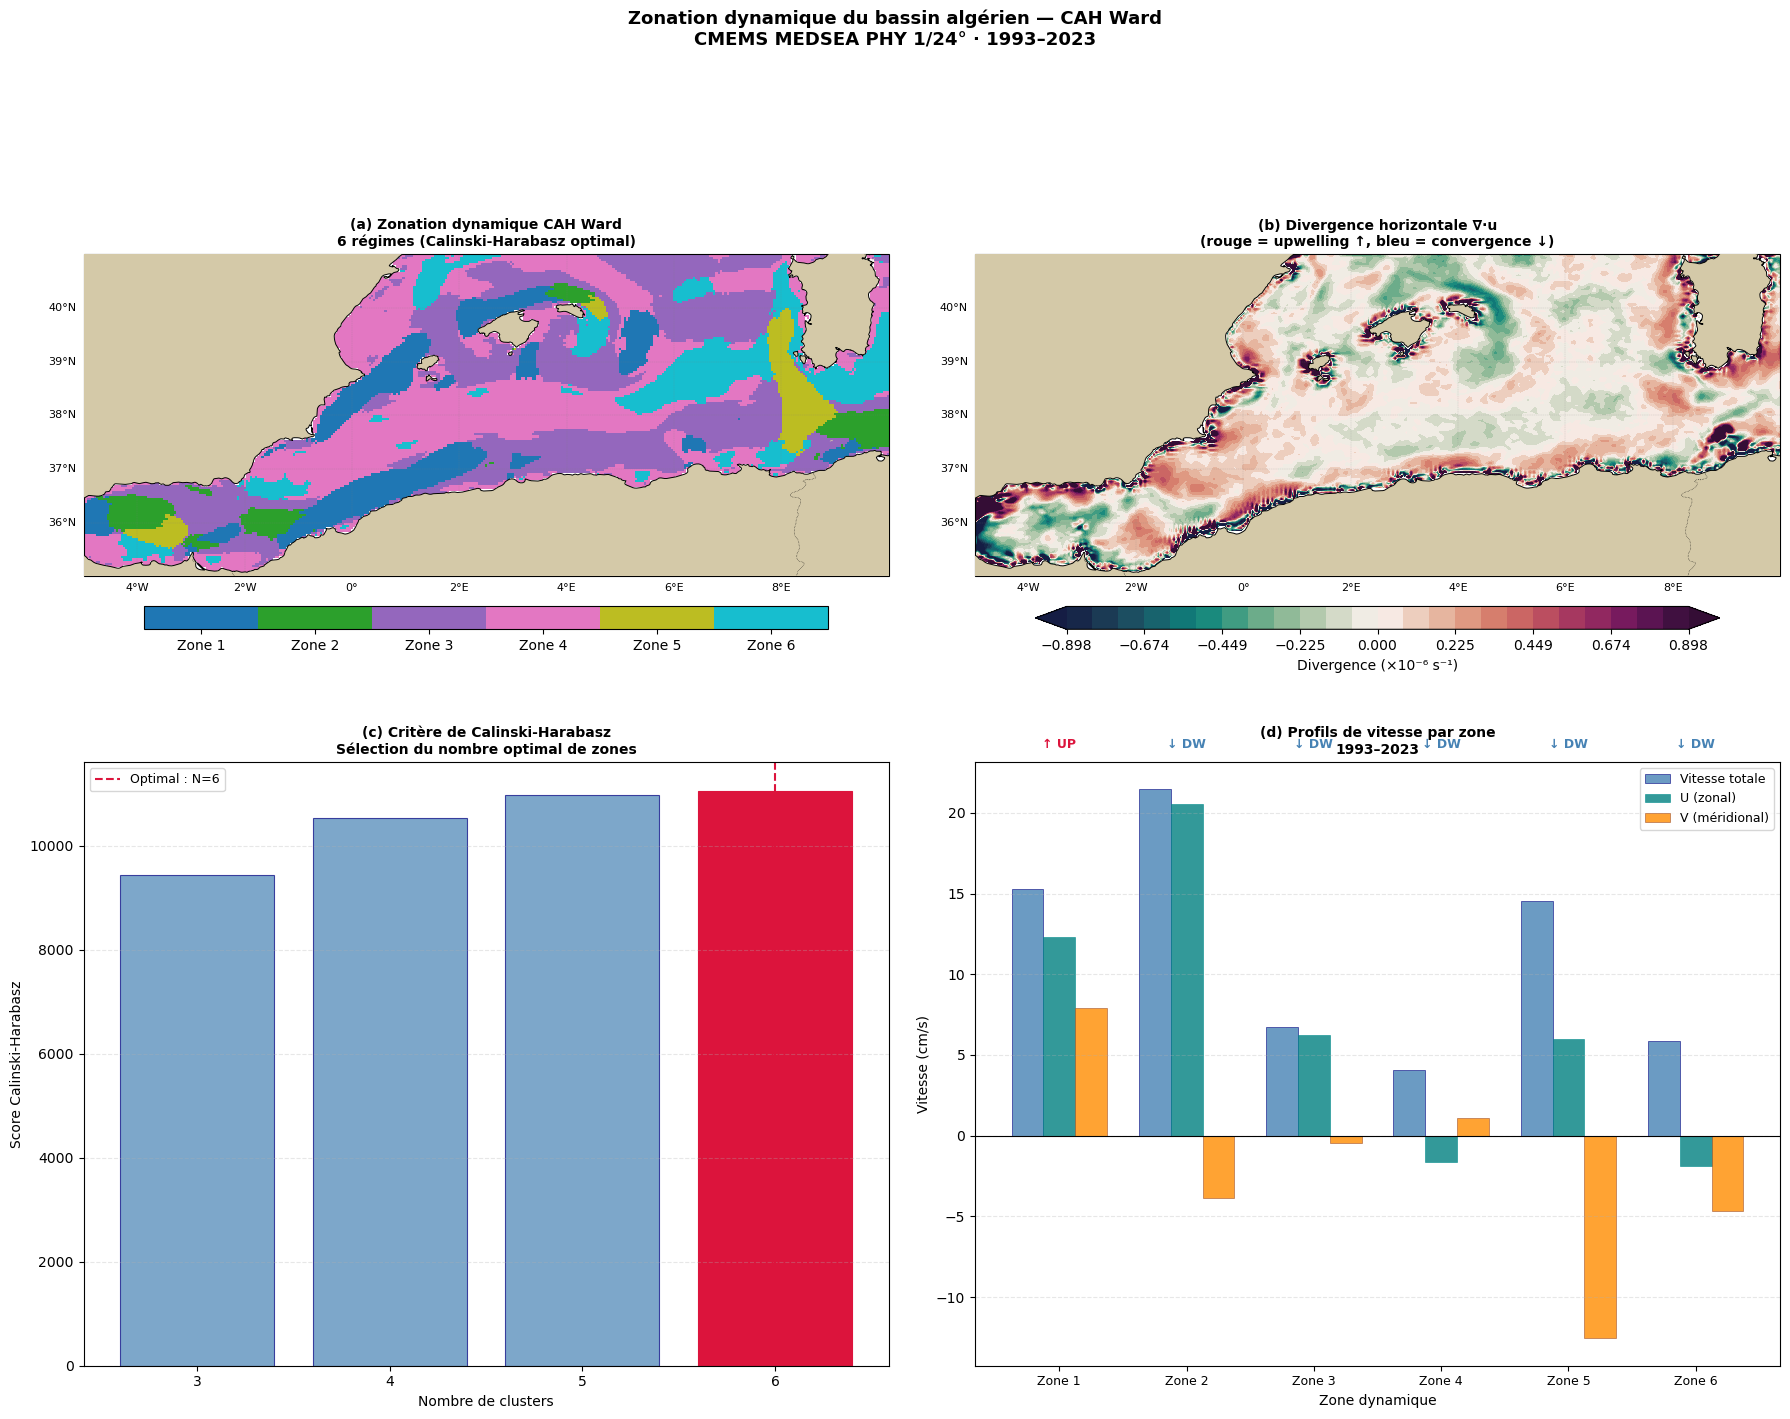


RÉSULTATS CAH — ZONATION BASSIN ALGÉRIEN
  Zone 1 :  3512 px | Speed=15.31 cm/s | ∇·u=+1.175e-02 ×10⁻⁶ s⁻¹ → UPWELLING ↑
  Zone 2 :  1308 px | Speed=21.45 cm/s | ∇·u=-8.082e-03 ×10⁻⁶ s⁻¹ → CONVERGENCE ↓
  Zone 3 :  8748 px | Speed=6.75 cm/s | ∇·u=-4.520e-02 ×10⁻⁶ s⁻¹ → CONVERGENCE ↓
  Zone 4 :  9065 px | Speed=4.05 cm/s | ∇·u=-1.315e-03 ×10⁻⁶ s⁻¹ → CONVERGENCE ↓
  Zone 5 :  1153 px | Speed=14.56 cm/s | ∇·u=-3.924e-02 ×10⁻⁶ s⁻¹ → CONVERGENCE ↓
  Zone 6 :  3573 px | Speed=5.88 cm/s | ∇·u=-1.147e-02 ×10⁻⁶ s⁻¹ → CONVERGENCE ↓


In [30]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import calinski_harabasz_score
from sklearn.preprocessing import StandardScaler
import os, warnings
warnings.filterwarnings('ignore')

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
FIG_DIR  = DATA_DIR + r"\FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

# ── Chargement ────────────────────────────────────────────────────────────
print("Chargement MEDSEA PHY courants...")
ds_cur = xr.open_dataset(
    DATA_DIR + r"\cmems_mod_med_phy-cur_my_4.2km_P1D-m_uo-vo"
               r"_5.00W-10.00E_35.02N-40.98N_1.02m_1993-01-01-2023-12-31.nc"
)

# ── Moyenne temporelle + squeeze ──────────────────────────────────────────
print("Calcul des moyennes annuelles...")
u_mean = ds_cur['uo'].mean('time').squeeze().values
v_mean = ds_cur['vo'].mean('time').squeeze().values
print(f"Forme après squeeze : {u_mean.shape}")

lats = ds_cur['latitude'].values
lons = ds_cur['longitude'].values

# ── Divergence ∇·u ────────────────────────────────────────────────────────
print("Calcul divergence ∇·u...")
dlat_m = np.abs(np.diff(lats).mean()) * 111000
dlon_m = np.abs(np.diff(lons).mean()) * 111000 * \
         np.cos(np.radians(np.mean(lats)))

# Remplacer NaN par 0 avant le gradient (pixels terre → 0)
u_for_grad = np.where(np.isnan(u_mean), 0.0, u_mean)
v_for_grad = np.where(np.isnan(v_mean), 0.0, v_mean)

du_dx = np.gradient(u_for_grad, dlon_m, axis=1)
dv_dy = np.gradient(v_for_grad, dlat_m, axis=0)
div   = du_dx + dv_dy

# Remettre NaN sur les pixels terre
div = np.where(np.isnan(u_mean) | np.isnan(v_mean), np.nan, div)

# ── Préparation CAH ───────────────────────────────────────────────────────
print("Préparation matrice features pour CAH...")
nlat, nlon  = u_mean.shape
mask_valid  = ~(np.isnan(u_mean) | np.isnan(v_mean))
print(f"Pixels valides (mer) : {mask_valid.sum()} / {nlat * nlon}")

u_flat   = u_mean[mask_valid]
v_flat   = v_mean[mask_valid]
div_flat = div[mask_valid]

X      = np.column_stack([u_flat, v_flat])
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

# ── Calinski-Harabasz — limité à N=6 max (lisibilité publication) ─────────
print("Recherche du nombre optimal de clusters (N=3 à 6)...")
Z = linkage(X_norm, method='ward')

ch_scores = {}
for n in range(3, 7):           # ← max 6 pour article publiable
    labels_test  = fcluster(Z, t=n, criterion='maxclust')
    ch_scores[n] = calinski_harabasz_score(X_norm, labels_test)
    print(f"  N={n} : CH={ch_scores[n]:.1f}")

n_optimal   = max(ch_scores, key=ch_scores.get)
print(f"\nNombre optimal de clusters : {n_optimal}")

# ── CAH finale ────────────────────────────────────────────────────────────
labels_flat = fcluster(Z, t=n_optimal, criterion='maxclust')
labels_2d   = np.full((nlat, nlon), np.nan)
labels_2d[mask_valid] = labels_flat

# ── Profils par cluster ───────────────────────────────────────────────────
print("\nProfils par cluster :")
cluster_stats = {}
for c in range(1, n_optimal + 1):
    mask_c = labels_flat == c
    u_c    = u_flat[mask_c]
    v_c    = v_flat[mask_c]
    speed  = np.sqrt(u_c**2 + v_c**2)
    div_c  = div_flat[mask_c]

    div_mean = np.nanmean(div_c)          # ← nanmean pour ignorer NaN résiduels
    cluster_stats[c] = {
        'n':      mask_c.sum(),
        'u_mean': np.nanmean(u_c),
        'v_mean': np.nanmean(v_c),
        'speed':  np.nanmean(speed),
        'div':    div_mean,
    }
    nan_pct = np.isnan(div_c).mean() * 100
    regime  = "UPWELLING ↑" if div_mean > 0 else "CONVERGENCE ↓"
    print(f"  Zone {c} : N={mask_c.sum():5d} px | "
          f"U={np.nanmean(u_c):+.4f} m/s | "
          f"V={np.nanmean(v_c):+.4f} m/s | "
          f"Speed={np.nanmean(speed):.4f} m/s | "
          f"∇·u={div_mean:+.3e} s⁻¹ → {regime} "
          f"(NaN div: {nan_pct:.1f}%)")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 5
# ═══════════════════════════════════════════════════════════════════════════
proj       = ccrs.PlateCarree()
LAND_COLOR = '#d4c9a8'
cmap_cah   = plt.cm.get_cmap('tab10', n_optimal)

fig = plt.figure(figsize=(18, 14))
fig.patch.set_facecolor('white')

def add_geo(ax):
    ax.add_feature(cfeature.LAND,      facecolor=LAND_COLOR, zorder=5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.7,         zorder=6)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', zorder=6)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                      color='gray', alpha=0.4, linestyle='--')
    gl.top_labels   = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# ── (a) Zonation CAH ──────────────────────────────────────────────────────
ax1 = fig.add_subplot(2, 2, 1, projection=proj)
ax1.set_extent([-5, 10, 35, 41], crs=proj)

im1 = ax1.pcolormesh(
    lons, lats, labels_2d,
    cmap=cmap_cah, vmin=0.5, vmax=n_optimal + 0.5,
    transform=proj
)
add_geo(ax1)
cb1 = plt.colorbar(im1, ax=ax1, orientation='horizontal',
                   pad=0.05, shrink=0.85, aspect=30)
cb1.set_ticks(range(1, n_optimal + 1))
cb1.set_ticklabels([f'Zone {c}' for c in range(1, n_optimal + 1)])
ax1.set_title(f'(a) Zonation dynamique CAH Ward\n'
              f'{n_optimal} régimes (Calinski-Harabasz optimal)',
              fontsize=10, fontweight='bold')

# ── (b) Divergence ────────────────────────────────────────────────────────
ax2 = fig.add_subplot(2, 2, 2, projection=proj)
ax2.set_extent([-5, 10, 35, 41], crs=proj)

div_plot = np.where(mask_valid, div, np.nan)
vmax_div = np.nanpercentile(np.abs(div_plot[~np.isnan(div_plot)]), 95)

cf2 = ax2.contourf(
    lons, lats, div_plot * 1e6,
    levels=np.linspace(-vmax_div * 1e6, vmax_div * 1e6, 25),
    cmap=cmocean.cm.curl, transform=proj, extend='both'
)
add_geo(ax2)
plt.colorbar(cf2, ax=ax2, orientation='horizontal',
             pad=0.05, shrink=0.85,
             label='Divergence (×10⁻⁶ s⁻¹)', aspect=30)
ax2.set_title('(b) Divergence horizontale ∇·u\n'
              '(rouge = upwelling ↑, bleu = convergence ↓)',
              fontsize=10, fontweight='bold')

# ── (c) Calinski-Harabasz ─────────────────────────────────────────────────
ax3 = fig.add_subplot(2, 2, 3)
ns   = list(ch_scores.keys())
chs  = list(ch_scores.values())
bars = ax3.bar(ns, chs, color='steelblue', alpha=0.7,
               edgecolor='navy', linewidth=0.8)
bars[n_optimal - min(ns)].set_color('crimson')
bars[n_optimal - min(ns)].set_alpha(1.0)
ax3.axvline(n_optimal, color='crimson', linewidth=1.5,
            linestyle='--', label=f'Optimal : N={n_optimal}')
ax3.set_xlabel('Nombre de clusters', fontsize=10)
ax3.set_ylabel('Score Calinski-Harabasz', fontsize=10)
ax3.set_title('(c) Critère de Calinski-Harabasz\n'
              'Sélection du nombre optimal de zones',
              fontsize=10, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3, linestyle='--', axis='y')
ax3.set_xticks(ns)

# ── (d) Profils par zone ──────────────────────────────────────────────────
ax4 = fig.add_subplot(2, 2, 4)
clusters = list(cluster_stats.keys())
speeds   = [cluster_stats[c]['speed']  * 100 for c in clusters]
u_vals   = [cluster_stats[c]['u_mean'] * 100 for c in clusters]
v_vals   = [cluster_stats[c]['v_mean'] * 100 for c in clusters]
div_vals = [cluster_stats[c]['div']    * 1e6 for c in clusters]

x     = np.arange(len(clusters))
width = 0.25

ax4.bar(x - width, speeds,  width, label='Vitesse totale',
        color='steelblue', alpha=0.8, edgecolor='navy', lw=0.5)
ax4.bar(x,          u_vals, width, label='U (zonal)',
        color='teal',        alpha=0.8, edgecolor='darkcyan', lw=0.5)
ax4.bar(x + width,  v_vals, width, label='V (méridional)',
        color='darkorange',  alpha=0.8, edgecolor='sienna', lw=0.5)

ax4.set_xlabel('Zone dynamique', fontsize=10)
ax4.set_ylabel('Vitesse (cm/s)', fontsize=10)
ax4.set_title('(d) Profils de vitesse par zone\n'
              '1993–2023', fontsize=10, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels([f'Zone {c}' for c in clusters], fontsize=9)
ax4.legend(fontsize=9)
ax4.axhline(0, color='black', linewidth=0.8)
ax4.grid(True, alpha=0.3, linestyle='--', axis='y')

# Annoter régime UP/DW
y_annot = max(max(speeds), max(u_vals), max(abs(v) for v in v_vals)) * 1.12
for i, c in enumerate(clusters):
    dv  = div_vals[i]
    txt = '↑ UP' if dv > 0 else '↓ DW'
    col = 'crimson' if dv > 0 else 'steelblue'
    ax4.text(i, y_annot, txt, ha='center', fontsize=9,
             color=col, fontweight='bold')

# ── Titre général ─────────────────────────────────────────────────────────
fig.suptitle(
    'Zonation dynamique du bassin algérien — CAH Ward\n'
    'CMEMS MEDSEA PHY 1/24° · 1993–2023',
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout(h_pad=3, w_pad=2)

OUTPUT = FIG_DIR + r"\Fig05_CAH_zonation_1993_2023.png"
plt.savefig(OUTPUT, dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print(f"\nFigure sauvegardée → {OUTPUT}")
plt.show()

# ── Résumé ────────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("RÉSULTATS CAH — ZONATION BASSIN ALGÉRIEN")
print("=" * 65)
for c in clusters:
    s = cluster_stats[c]
    regime = "UPWELLING ↑" if s['div'] > 0 else "CONVERGENCE ↓"
    print(f"  Zone {c} : {s['n']:5d} px | "
          f"Speed={s['speed']*100:.2f} cm/s | "
          f"∇·u={s['div']*1e6:+.3e} ×10⁻⁶ s⁻¹ → {regime}")
print("=" * 65)

ds_cur.close()

In [34]:
import py_eddy_tracker
import xarray as xr
import numpy as np
import os

print(f"py-eddy-tracker version : {py_eddy_tracker.__version__}")

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"

# ── Inspection du fichier allsat ──────────────────────────────────────────
ds = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)

print("\n── Variables disponibles ──────────────────────────────────────────")
for var in ds.data_vars:
    print(f"  {var:15s} : {ds[var].dims} — {ds[var].attrs.get('long_name','')}")

print("\n── Dimensions ────────────────────────────────────────────────────")
print(f"  time      : {len(ds.time)} pas de temps")
print(f"  latitude  : {len(ds.latitude)} points — [{float(ds.latitude.min()):.2f} → {float(ds.latitude.max()):.2f}]")
print(f"  longitude : {len(ds.longitude)} points — [{float(ds.longitude.min()):.2f} → {float(ds.longitude.max()):.2f}]")
print(f"  Résolution: {float(np.diff(ds.longitude).mean()):.4f}°")

print("\n── Test ADT (requis pour py-eddy-tracker) ────────────────────────")
adt_sample = ds['adt'].isel(time=0)
nan_pct    = float(adt_sample.isnull().mean() * 100)
print(f"  ADT : min={float(adt_sample.min(skipna=True)):.4f} m | "
      f"max={float(adt_sample.max(skipna=True)):.4f} m | "
      f"NaN={nan_pct:.1f}%")

print("\n── Vérification MDT ──────────────────────────────────────────────")
ds_mdt = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_eur_phy-mdt_my_l4-0.0625deg_P20Y"
               r"_mdt-v-u_4.97W-9.97E_35.03N-40.97N_2003-01-01.nc"
)
mdt_2d = ds_mdt['mdt'].squeeze()
print(f"  MDT : min={float(mdt_2d.min(skipna=True)):.4f} m | "
      f"max={float(mdt_2d.max(skipna=True)):.4f} m")
print(f"  MDT résolution : {float(np.diff(ds_mdt.longitude).mean()):.5f}°")

print("\n── Format de date (critique pour py-eddy-tracker) ───────────────")
print(f"  Premier pas : {str(ds.time.values[0])[:19]}")
print(f"  Dernier pas : {str(ds.time.values[-1])[:19]}")
print(f"  Type        : {ds.time.dtype}")

ds.close()
ds_mdt.close()
print("\n✅ Environnement prêt pour py-eddy-tracker")

py-eddy-tracker version : v3.6.1

── Variables disponibles ──────────────────────────────────────────
  adt             : ('time', 'latitude', 'longitude') — Absolute dynamic topography
  sla             : ('time', 'latitude', 'longitude') — Sea level anomaly
  ugos            : ('time', 'latitude', 'longitude') — Absolute geostrophic velocity: zonal component
  vgos            : ('time', 'latitude', 'longitude') — Absolute geostrophic velocity: meridian component
  vgosa           : ('time', 'latitude', 'longitude') — Geostrophic velocity anomalies: meridian component
  ugosa           : ('time', 'latitude', 'longitude') — Geostrophic velocity anomalies: zonal component
  err_sla         : ('time', 'latitude', 'longitude') — Formal mapping error

── Dimensions ────────────────────────────────────────────────────
  time      : 11322 pas de temps
  latitude  : 48 points — [35.06 → 40.94]
  longitude : 120 points — [-4.94 → 9.94]
  Résolution: 0.1250°

── Test ADT (requis pour py-eddy-tr

In [44]:
import xarray as xr
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.observations.observation import EddiesObservations

DATA_DIR = r"C:\Users\kikk\CLAUDE ARTICLE DATA"
EDDY_DIR = DATA_DIR + r"\EDDIES"
TEMP_DIR = EDDY_DIR + r"\TEMP"
os.makedirs(TEMP_DIR, exist_ok=True)

# ── Chargement du fichier allsat ──────────────────────────────────────────
print("Chargement allsat...")
ds = xr.open_dataset(
    DATA_DIR + r"\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg"
               r"_P1D_multi-vars_4.94W-9.94E_35.06N-40.94N_1993-01-01-2023-12-31.nc"
)

# ── TEST SUR 30 PREMIERS JOURS ────────────────────────────────────────────
print("\nTest de détection sur 30 jours (1993-01-01 → 1993-01-30)...")
print("─" * 60)

anticyclonic_list = []
cyclonic_list     = []
errors            = []

for i in range(30):
    date = ds.time.values[i]
    date_str = str(date)[:10]

    # Extraire le pas de temps → fichier NetCDF temporaire
    ds_day = ds[['adt', 'ugos', 'vgos']].isel(time=i)
    
    # py-eddy-tracker a besoin d'un fichier avec longitude/latitude comme dims
    tmp_file = os.path.join(TEMP_DIR, f"adt_{date_str}.nc")
    ds_day.to_netcdf(tmp_file)

    try:
        # Charger avec py-eddy-tracker
        g = RegularGridDataset(tmp_file, 'longitude', 'latitude')

        # Filtre passe-haut Bessel 700 km
        # (retire la grande échelle, conserve la méso-échelle)
        g.bessel_high_filter('adt', 700)

        # Détection des eddies
        # Paramètres optimaux Méditerranée :
        #   step=0.002 m (2 mm entre contours)
        #   shape_error=55 (tolérance de forme en %)
        a, c = g.eddy_identification(
            'adt', 'ugos', 'vgos',
            date,
            0.002,    # pas entre contours (m)
            55,       # tolérance de forme (%)
        )

        n_a = len(a) if a is not None else 0
        n_c = len(c) if c is not None else 0

        if a is not None and len(a) > 0:
            anticyclonic_list.append(a)
        if c is not None and len(c) > 0:
            cyclonic_list.append(c)

        print(f"  {date_str} : {n_a:2d} anticyclones | {n_c:2d} cyclones")

    except Exception as e:
        errors.append((date_str, str(e)))
        print(f"  {date_str} : ERREUR → {str(e)[:60]}")

    finally:
        # Nettoyage fichier temporaire
        if os.path.exists(tmp_file):
            os.remove(tmp_file)

# ── Résumé du test ────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("RÉSUMÉ DU TEST (30 jours)")
print("=" * 60)
print(f"  Jours traités avec succès : {30 - len(errors)}/30")
print(f"  Erreurs                   : {len(errors)}")
if errors:
    for d, e in errors:
        print(f"    {d} : {e[:80]}")

if anticyclonic_list:
    total_a = sum(len(a) for a in anticyclonic_list)
    total_c = sum(len(c) for c in cyclonic_list)
    print(f"  Total anticyclones détectés : {total_a}")
    print(f"  Total cyclones détectés     : {total_c}")
    print(f"  Moyenne par jour            : "
          f"{total_a/len(anticyclonic_list):.1f} anti | "
          f"{total_c/max(len(cyclonic_list),1):.1f} cyc")
    print("\n✅ Détection fonctionnelle — prêt pour l'analyse complète")
else:
    print("\n❌ Aucun eddy détecté — vérifier les paramètres")

ds.close()

ModuleNotFoundError: No module named 'Polygon'